# <span style="color:#990000;"> Los Angeles Airbnb Pricing Analysis</span> #

## Project Overview

This project analyzes Airbnb listings in Los Angeles County to examine pricing trends and the relationship between nightly rates and listing characteristics. The analysis focuses on factors such as property type, location, guest capacity, and host characteristics, with the goal of identifying patterns relevant to short-term rental investment decisions.

The analysis uses Python for data cleaning, exploratory data analysis (EDA), statistical inference, and probability distribution modeling.

**Data Source:** Inside Airbnb, Los Angeles County listings (March 2025).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import lognorm

In [2]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.set_option('display.max_rows', 100)

## Data Overview
The dataset contains 45,031 Airbnb listings in Los Angeles County, with information on pricing, property characteristics, location, host details, and booking requirements.

The initial data inspection examines column types, missing values, and summary statistics to identify potential data quality issues and select relevant features for analysis.

In [3]:
listings = pd.read_csv("../data/aan505_fa_listings.csv")

In [4]:
listings.shape

(45031, 79)

In [5]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45031 entries, 0 to 45030
Data columns (total 79 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            45031 non-null  int64  
 1   listing_url                                   45031 non-null  object 
 2   scrape_id                                     45031 non-null  int64  
 3   last_scraped                                  45031 non-null  int64  
 4   source                                        45031 non-null  object 
 5   name                                          45030 non-null  object 
 6   description                                   43998 non-null  object 
 7   neighborhood_overview                         21333 non-null  object 
 8   picture_url                                   45031 non-null  object 
 9   host_id                                       45031 non-null 

In [6]:
listings.describe()

,id,scrape_id,last_scraped,host_id,host_since,host_response_rate,host_acceptance_rate,host_listings_count,host_total_listings_count,latitude,...,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,45031.00,45031.00,45031.00,45031.00,44958.00,34627.00,35297.00,44958.00,44958.00,45031.00,...,32375.00,32367.00,32373.00,32366.00,32365.00,45031.00,45031.00,45031.00,45031.00,32383.00
mean,601559069999122176.00,20250301213405.00,45718.78,204958169.98,43070.76,0.96,0.86,112.42,147.67,34.06,...,4.75,4.86,4.86,4.80,4.71,19.40,16.12,2.61,0.07,1.35
std,543550256222122880.00,0.00,0.41,201969803.85,1349.95,0.16,0.23,664.73,795.52,0.14,...,0.43,0.35,0.37,0.38,0.44,68.99,67.93,10.28,0.95,1.70
min,2708.00,20250301213405.00,45718.00,767.00,39640.00,0.00,0.00,0.00,0.00,33.34,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.01
25%,35590983.00,20250301213405.00,45719.00,27484084.50,42062.00,1.00,0.83,1.00,2.00,34.00,...,4.69,4.87,4.88,4.75,4.66,1.00,1.00,0.00,0.00,0.20
50%,719922311521336448.00,20250301213405.00,45719.00,119676461.00,42810.00,1.00,0.97,3.00,5.00,34.06,...,4.88,4.97,4.98,4.91,4.82,2.00,1.00,0.00,0.00,0.70
75%,1131383744101344768.00,20250301213405.00,45719.00,383790851.00,44205.00,1.00,1.00,13.00,19.00,34.11,...,5.00,5.00,5.00,5.00,4.96,10.00,5.00,1.00,0.00,2.02
max,1366923674056931328.00,20250301213405.00,45719.00,681576491.00,45716.00,1.00,1.00,5255.00,9055.00,34.81,...,5.00,5.00,5.00,5.00,5.00,582.00,582.00,100.00,19.00,68.52


In [7]:
listings.isnull().sum()

id                                                  0
listing_url                                         0
scrape_id                                           0
last_scraped                                        0
source                                              0
name                                                1
description                                      1033
neighborhood_overview                           23698
picture_url                                         0
host_id                                             0
host_url                                            0
host_name                                          70
host_since                                         73
host_location                                   10557
host_about                                      20507
host_response_time                              10404
host_response_rate                              10404
host_acceptance_rate                             9734
host_is_superhost           

In [8]:
listings.duplicated().sum()

np.int64(0)

In [9]:
listings.iloc[:, 0:5].head()

,id,listing_url,scrape_id,last_scraped,source
0,75212,https://www.airbnb.com/rooms/75212,20250301213405,45719,city scrape
1,76561,https://www.airbnb.com/rooms/76561,20250301213405,45719,city scrape
2,79502,https://www.airbnb.com/rooms/79502,20250301213405,45719,city scrape
3,79832,https://www.airbnb.com/rooms/79832,20250301213405,45718,city scrape
4,80714,https://www.airbnb.com/rooms/80714,20250301213405,45719,city scrape


The listing_url column can be removed because it only contains a link for each listing so it's not relevant to price.

In [10]:
listings.iloc[:, 5:10].head()

,name,description,neighborhood_overview,picture_url,host_id
0,Sunny Room only in town house nr Long Beach…,"A bright & sunny room ONLY with full size bed,...","A really lovely area, with so many restaurants...",https://a0.muscache.com/pictures/e3cff12f-d518...,343761
1,420 Friendly Sweet Lil' Guesthouse by Sofi & LAX,-420 Friendly Airbnb Stay in LA!-<br />(16 to ...,Q: WHAT'S THE NEIGHBORHOOD LIKE?<br /><br />A:...,https://a0.muscache.com/pictures/23627d22-d977...,403838
2,Silver Lake million dollar view * luxe patio,"Walk to Sunset Junction, the Polka Dot triangl...",We have the absolute iconic views of downtown...,https://a0.muscache.com/pictures/miso/Hosting-...,428171
3,Guest Quarters @ the Hollywood Sign,Guest House,NaN,https://a0.muscache.com/pictures/541078/35c6dc...,28569
4,Cozy secluded Guesthouse in Garden,Sierra Bonita Guesthouse in Garden setting:<br...,We are very central to so many tourist destina...,https://a0.muscache.com/pictures/2080263/2d8a6...,436647


I would remove picture_url because the link itself isn't relevant to price. Analyzing the photos would require image processing. I would also exclude description and neighbourhood_overview because they require more sophisticated processing to extract useful information from the written descriptions.

In [11]:
listings.iloc[:, 10:15].head()

,host_url,host_name,host_since,host_location,host_about
0,https://www.airbnb.com/users/show/343761,Kris,40554.00,"Lakewood, CA","My Mott (Website hidden by Airbnb) ""LISLIN"" LI..."
1,https://www.airbnb.com/users/show/403838,Jennifer,40596.00,"Los Angeles, CA",Airbnb Host since 2Oll.\n2051+ Rave Reviews \...
2,https://www.airbnb.com/users/show/428171,H.,40609.00,"Los Angeles, CA","Inventive, friendly, design enthusiast, indie ..."
3,https://www.airbnb.com/users/show/28569,Robert,40023.00,"Los Angeles, CA",NaN
4,https://www.airbnb.com/users/show/436647,Cari,40613.00,"Los Angeles, CA",...Pronouced like a car with and ee at the end...


I would remove host_url because the profile link isn't relevant to price. I would also exclude host_about because it requires more sophisticated processing to identify useful information from the written descriptions. The host_since column requires a data type transformation because its dates are stored as numbers. I would need to convert these into dates if I decide to keep it.

In [12]:
listings.iloc[:, 15:20].head()

,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url
0,within an hour,1.00,0.69,f,https://a0.muscache.com/im/pictures/user/a8222...
1,within an hour,1.00,0.99,t,https://a0.muscache.com/im/pictures/user/User-...
2,within an hour,1.00,0.82,t,https://a0.muscache.com/im/pictures/user/99275...
3,within a day,1.00,NaN,f,https://a0.muscache.com/im/users/28569/profile...
4,within a few hours,1.00,0.63,f,https://a0.muscache.com/im/users/436647/profil...


I would consider keeping host_is_superhost because Superhost status may be related to price. It requires a value transformation because it uses t and f which I could convert to 1 and 0.

In [13]:
listings.iloc[:, 20:25].head()

,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications
0,https://a0.muscache.com/im/pictures/user/a8222...,Cerritos,1.00,2.00,"['email', 'phone']"
1,https://a0.muscache.com/im/pictures/user/User-...,South LA,4.00,4.00,"['email', 'phone']"
2,https://a0.muscache.com/im/pictures/user/99275...,Silver Lake,3.00,3.00,"['email', 'phone']"
3,https://a0.muscache.com/im/users/28569/profile...,Hollywood Hills,1.00,1.00,"['email', 'phone']"
4,https://a0.muscache.com/im/users/436647/profil...,Mid-Wilshire,1.00,1.00,"['email', 'phone']"


In [14]:
listings.iloc[:, 25:30].head()

,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed
0,t,t,Neighborhood highlights,Lakewood,Other Cities
1,t,t,Neighborhood highlights,View Park-Windsor Hills,Unincorporated Areas
2,t,t,Neighborhood highlights,Silver Lake,City of Los Angeles
3,t,t,NaN,Hollywood Hills,City of Los Angeles
4,t,t,Neighborhood highlights,Mid-Wilshire,City of Los Angeles


The host_has_profile_pic and host_identity_verified columns require value transformations because they use t and f. I could convert these to 1 and 0 if I decide to keep them.

In [15]:
listings.iloc[:, 30:35].head()

,latitude,longitude,property_type,room_type,accommodates
0,33.85,-118.08,Private room in townhouse,Private room,2
1,33.99,-118.36,Entire guesthouse,Entire home/apt,3
2,34.08,-118.28,Entire vacation home,Entire home/apt,2
3,34.13,-118.32,Entire home,Entire home/apt,2
4,34.06,-118.36,Entire rental unit,Entire home/apt,1


In [16]:
listings.iloc[:, 35:40].head()

,bathrooms,bathrooms_text,bedrooms,beds,amenities
0,1.00,1 shared bath,1.00,1.00,"[""Books and reading material"", ""Microwave"", ""F..."
1,1.00,1 bath,0.00,3.00,"[""Books and reading material"", ""Microwave"", ""F..."
2,1.00,1 bath,1.00,1.00,"[""Microwave"", ""Fire extinguisher"", ""Hot water""..."
3,NaN,NaN,1.00,1.00,"[""Private entrance"", ""Free parking on premises..."
4,1.00,1 bath,1.00,3.00,"[""Microwave"", ""Hot water"", ""Essentials"", ""Stov..."


I would exclude bathrooms_text because it requires more sophisticated processing to separate the bathroom count from details about shared or private bathrooms. I would also exclude amenities because each entry contains multiple features that would need to be separated before analyzing their relationship with price.

In [17]:
listings.iloc[:, 40:45].head()

,price,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights
0,65.00,2,28,2.00,2.00
1,109.00,2,14,2.00,2.00
2,106.00,30,175,30.00,30.00
3,110.00,30,730,30.00,30.00
4,109.00,30,60,30.00,30.00


In [18]:
listings.iloc[:, 45:50].head()

,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated
0,28.00,28.00,2.00,28.00,NaN
1,14.00,14.00,2.00,14.00,NaN
2,175.00,175.00,30.00,175.00,NaN
3,730.00,730.00,30.00,730.00,NaN
4,60.00,60.00,30.00,60.00,NaN


I would remove calendar_updated because it's completely empty and has no information to analyze.

In [19]:
listings.iloc[:, 50:55].head()

,has_availability,availability_30,availability_60,availability_90,availability_365
0,t,21,38,56,330
1,t,14,40,51,136
2,t,25,55,85,360
3,t,0,0,0,60
4,t,2,32,62,337


In [20]:
listings.iloc[:, 55:60].head()

,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy
0,45719,77,7,0,269
1,45719,902,60,4,136
2,45719,300,2,0,299
3,45718,483,0,0,0
4,45719,197,5,0,276


In [21]:
listings.iloc[:, 60:65].head()

,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review
0,6,42,2730.00,40654.00,45669.00
1,66,255,27795.00,40618.00,45704.00
2,2,120,12720.00,40664.00,45575.00
3,0,0,0.00,40621.00,44214.00
4,5,255,27795.00,40623.00,45643.00


I would remove estimated_revenue_l365d because it could introduce predictive leakage. Estimated revenue uses pricing information, so including it in a model predicting nightly price could make the results misleading. The first_review and last_review columns require data type transformations because their dates are stored as numbers. I would convert them into dates if I decide to keep them.

In [22]:
listings.iloc[:, 65:70].head()

,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication
0,4.84,4.92,4.91,4.95,4.96
1,4.83,4.85,4.68,4.95,4.94
2,4.82,4.85,4.89,4.95,4.88
3,4.90,4.89,4.77,4.96,4.95
4,4.95,4.93,4.96,4.97,4.98


In [23]:
listings.iloc[:, 70:75].head()

,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count
0,4.89,4.83,NaN,f,1
1,4.70,4.79,NaN,f,4
2,4.94,4.73,NaN,f,2
3,4.93,4.91,HSR19-002716,f,1
4,4.95,4.88,HSR19-003488,f,1


In [24]:
listings.iloc[:, 75:79].head()

,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,0,1,0,0.46
1,4,0,0,5.30
2,2,0,0,1.78
3,1,0,0,2.84
4,1,0,0,1.16


I started by using .shape to check the size of the dataset and info() to see how the columns were stored. The dataset contains 45,031 listings and 79 columns, with a mix of numeric and object data types. I then used describe() to understand the range of values and identify anything unusual. The maximum price was 99,999, which seems unusually high and should be investigated during cleaning. I used isnull().sum() to check how complete the data was and found 9,164 missing prices, along with missing information in several property and review columns. The calendar_updated column was completely empty. I also used duplicated().sum() to check whether any records were repeated and found no exact duplicate rows. I then reviewed the columns in groups of five to understand what each contained and identify features that might need to be removed or cleaned.

Reviewing the columns helped me decide which features to keep and what preparation would be needed in the next steps. I would remove URLs and identifiers because they're not relevant to price. I would also exclude written descriptions and amenities because they require more sophisticated processing to extract information that could be analyzed. Some columns require data type or value transformations, including dates stored as numbers and yes/no fields recorded as t and f. I would exclude estimated revenue because it uses pricing information and could introduce predictive leakage. I plan to keep location and property characteristics to examine how they relate to nightly prices.

In [25]:
columns_to_keep = [
    "price",
    "neighbourhood_cleansed",
    "neighbourhood_group_cleansed",
    "room_type",
    "property_type",
    "accommodates",
    "bedrooms",
    "bathrooms",
    "beds",
    "minimum_nights",
    "number_of_reviews",
    "review_scores_rating",
    "host_is_superhost",
    "instant_bookable"
]

In [26]:
listings = listings[columns_to_keep]

I kept price as the main variable because I want to understand what factors are associated with nightly Airbnb rates. I selected the neighbourhood columns to examine how prices vary across different areas of Los Angeles. I also kept room_type and property_type because the kind of accommodation may influence its price. The number of guests a listing accommodates, along with its bedrooms, bathrooms, and beds, can help me examine how property size relates to pricing. I included minimum_nights because booking requirements may affect how hosts set their rates. I also kept the number of reviews and review ratings to explore whether guest feedback is associated with price. Additionally, I included host_is_superhost and instant_bookable to examine whether host status and booking options have any relationship with nightly rates.

I also considered keeping amenities because features such as parking or a pool may help explain differences in nightly prices. However, the column contains multiple amenities stored together as text and would require more sophisticated processing to analyze each feature separately. I also considered keeping description because it contains information about the property's features that may affect pricing. Since these descriptions vary across listings, I would need to use text processing to identify relevant details and organize them into variables for analysis so I excluded it. I did keep host_is_superhost and instant_bookable though because their t and f values can be converted to 1 and 0 during cleaning.

## Data Cleaning and Preparation
The dataset was cleaned to address missing values, inconsistent data types, and anomalous observations. Relevant variables were selected for the analysis, and categorical features were converted where necessary.

Records with missing or implausible values were removed based on the data quality checks documented below.

In [27]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45031 entries, 0 to 45030
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   price                         35867 non-null  float64
 1   neighbourhood_cleansed        45031 non-null  object 
 2   neighbourhood_group_cleansed  45031 non-null  object 
 3   room_type                     45031 non-null  object 
 4   property_type                 45031 non-null  object 
 5   accommodates                  45031 non-null  int64  
 6   bedrooms                      42037 non-null  float64
 7   bathrooms                     35923 non-null  float64
 8   beds                          35808 non-null  float64
 9   minimum_nights                45031 non-null  int64  
 10  number_of_reviews             45031 non-null  int64  
 11  review_scores_rating          32383 non-null  float64
 12  host_is_superhost             43513 non-null  object 
 13  i

In [28]:
listings.head()

,price,neighbourhood_cleansed,neighbourhood_group_cleansed,room_type,property_type,accommodates,bedrooms,bathrooms,beds,minimum_nights,number_of_reviews,review_scores_rating,host_is_superhost,instant_bookable
0,65.00,Lakewood,Other Cities,Private room,Private room in townhouse,2,1.00,1.00,1.00,2,77,4.84,f,f
1,109.00,View Park-Windsor Hills,Unincorporated Areas,Entire home/apt,Entire guesthouse,3,0.00,1.00,3.00,2,902,4.83,t,f
2,106.00,Silver Lake,City of Los Angeles,Entire home/apt,Entire vacation home,2,1.00,1.00,1.00,30,300,4.82,t,f
3,110.00,Hollywood Hills,City of Los Angeles,Entire home/apt,Entire home,2,1.00,NaN,1.00,30,483,4.90,f,f
4,109.00,Mid-Wilshire,City of Los Angeles,Entire home/apt,Entire rental unit,1,1.00,1.00,3.00,30,197,4.95,f,f


In [29]:
listings["host_is_superhost"] = listings["host_is_superhost"].map({"t": 1, "f": 0})
listings["instant_bookable"] = listings["instant_bookable"].map({"t": 1, "f": 0})

In [30]:
listings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45031 entries, 0 to 45030
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   price                         35867 non-null  float64
 1   neighbourhood_cleansed        45031 non-null  object 
 2   neighbourhood_group_cleansed  45031 non-null  object 
 3   room_type                     45031 non-null  object 
 4   property_type                 45031 non-null  object 
 5   accommodates                  45031 non-null  int64  
 6   bedrooms                      42037 non-null  float64
 7   bathrooms                     35923 non-null  float64
 8   beds                          35808 non-null  float64
 9   minimum_nights                45031 non-null  int64  
 10  number_of_reviews             45031 non-null  int64  
 11  review_scores_rating          32383 non-null  float64
 12  host_is_superhost             43513 non-null  float64
 13  i

After checking the data types, I found that host_is_superhost and instant_bookable needed to be processed because they were stored as text values. Both columns used t and f to indicate true or false so I converted them to 1 and 0 to make them easier to use in the analysis. The other categorical variables can remain as text since I can use them to compare prices across different groups of listings.

### Missing Values

In [31]:
listings.dropna()

,price,neighbourhood_cleansed,neighbourhood_group_cleansed,room_type,property_type,accommodates,bedrooms,bathrooms,beds,minimum_nights,number_of_reviews,review_scores_rating,host_is_superhost,instant_bookable
0,65.00,Lakewood,Other Cities,Private room,Private room in townhouse,2,1.00,1.00,1.00,2,77,4.84,0.00,0
1,109.00,View Park-Windsor Hills,Unincorporated Areas,Entire home/apt,Entire guesthouse,3,0.00,1.00,3.00,2,902,4.83,1.00,0
2,106.00,Silver Lake,City of Los Angeles,Entire home/apt,Entire vacation home,2,1.00,1.00,1.00,30,300,4.82,1.00,0
4,109.00,Mid-Wilshire,City of Los Angeles,Entire home/apt,Entire rental unit,1,1.00,1.00,3.00,30,197,4.95,0.00,0
7,109.00,West Los Angeles,City of Los Angeles,Entire home/apt,Entire rental unit,4,1.00,1.00,1.00,30,41,4.51,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44777,107.00,Torrance,Other Cities,Private room,Private room in home,2,1.00,1.00,1.00,1,1,5.00,0.00,0
44807,62.00,Rowland Heights,Unincorporated Areas,Private room,Private room in home,2,1.00,0.50,1.00,1,2,5.00,0.00,0
44845,59.00,Duarte,Other Cities,Entire home/apt,Entire guest suite,2,1.00,1.00,1.00,1,1,5.00,0.00,0
44899,104.00,Culver City,Other Cities,Private room,Private room in home,2,1.00,1.00,1.00,1,1,5.00,0.00,0


### Outliers and Data Validation
Numerical features were examined for extreme values and potential inconsistencies. Unusual observations were reviewed alongside related property characteristics to determine whether they represented plausible listings or potential data errors.

In [32]:
listings.describe().T

,count,mean,std,min,25%,50%,75%,max
price,35867.00,285.90,862.52,9.00,92.00,150.00,258.00,99999.00
accommodates,45031.00,4.06,2.89,1.00,2.00,3.00,6.00,16.00
bedrooms,42037.00,1.80,1.34,0.00,1.00,1.00,2.00,43.00
bathrooms,35923.00,1.65,1.24,0.00,1.00,1.00,2.00,47.50
beds,35808.00,2.26,1.77,0.00,1.00,2.00,3.00,50.00
minimum_nights,45031.00,18.71,30.66,1.00,2.00,28.00,30.00,1124.00
number_of_reviews,45031.00,37.17,82.72,0.00,0.00,5.00,34.00,3061.00
review_scores_rating,32383.00,4.79,0.41,0.00,4.75,4.91,5.00,5.00
host_is_superhost,43513.00,0.36,0.48,0.00,0.00,0.00,1.00,1.00
instant_bookable,45031.00,0.25,0.43,0.00,0.00,0.00,1.00,1.00


In [33]:
listings.describe(include="object").T

,count,unique,top,freq
neighbourhood_cleansed,45031,266,Long Beach,1864
neighbourhood_group_cleansed,45031,3,City of Los Angeles,22377
room_type,45031,4,Entire home/apt,32954
property_type,45031,95,Entire home,12666


In [34]:
listings.sort_values("price", ascending=False).head(10)

,price,neighbourhood_cleansed,neighbourhood_group_cleansed,room_type,property_type,accommodates,bedrooms,bathrooms,beds,minimum_nights,number_of_reviews,review_scores_rating,host_is_superhost,instant_bookable
20594,99999.00,El Monte,Other Cities,Private room,Private room in townhouse,1,1.00,1.00,1.00,365,1,5.00,1.00,0
32609,30000.00,Malibu,Other Cities,Entire home/apt,Entire home,16,16.00,16.00,16.00,30,0,NaN,0.00,0
44352,27000.00,Studio City,City of Los Angeles,Entire home/apt,Entire home,8,4.00,4.50,0.00,30,0,NaN,0.00,0
6469,21053.00,Bel-Air,City of Los Angeles,Entire home/apt,Entire villa,16,9.00,12.50,10.00,30,0,NaN,0.00,0
20662,17600.00,Manhattan Beach,Other Cities,Entire home/apt,Entire vacation home,8,4.00,3.50,5.00,30,0,NaN,1.00,0
39780,17200.00,Fairfax,City of Los Angeles,Entire home/apt,Entire home,8,4.00,3.00,4.00,30,0,NaN,0.00,0
7525,16903.00,Studio City,City of Los Angeles,Entire home/apt,Entire home,12,5.00,5.50,6.00,30,34,4.68,0.00,0
27797,16500.00,Malibu,Other Cities,Entire home/apt,Entire home/apt,16,8.00,8.00,8.00,30,0,NaN,0.00,0
8352,15607.00,Beverly Hills,Other Cities,Entire home/apt,Entire villa,12,7.00,12.00,7.00,3,5,5.00,0.00,0
32079,15525.00,Malibu,Other Cities,Entire home/apt,Entire home,14,7.00,9.50,7.00,5,1,5.00,0.00,0


- The price column contains some extreme values, with a median of \\$150 and a maximum of \\$99,999
   - The most expensive listing is a private room in El Monte for one guest with a 365 night minimum stay but its price is still unusually high and should be double checked for accuracy
- The bedrooms, bathrooms, and beds columns have maximum values of 43, 47.5, and 50, respectively, which are much higher than their medians of 1, 1, and 2.
  - These values could be accurate but they should be checked for possible errors.
- The minimum_nights column has a maximum of 1,124 nights compared with a median of 28 which seems unusually long even for a rental intended for longer stays.
- The number_of_reviews column has a maximum of 3,061 compared with a median of 5, although this could be reasonable for listings that have been active for several years.
- The review_scores_rating column has a minimum of 0 and a median of 4.91 so it would be useful to check whether the zero ratings are valid.
- A listing in Studio City costs $27,000 and accommodates eight guests but has zero beds recorded which seems inconsistent with the listing details.

In [35]:
listings.sort_values("price", ascending=False).head(10).T

,20594,32609,44352,6469,20662,39780,7525,27797,8352,32079
price,99999.00,30000.00,27000.00,21053.00,17600.00,17200.00,16903.00,16500.00,15607.00,15525.00
neighbourhood_cleansed,El Monte,Malibu,Studio City,Bel-Air,Manhattan Beach,Fairfax,Studio City,Malibu,Beverly Hills,Malibu
neighbourhood_group_cleansed,Other Cities,Other Cities,City of Los Angeles,City of Los Angeles,Other Cities,City of Los Angeles,City of Los Angeles,Other Cities,Other Cities,Other Cities
room_type,Private room,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt
property_type,Private room in townhouse,Entire home,Entire home,Entire villa,Entire vacation home,Entire home,Entire home,Entire home/apt,Entire villa,Entire home
accommodates,1,16,8,16,8,8,12,16,12,14
bedrooms,1.00,16.00,4.00,9.00,4.00,4.00,5.00,8.00,7.00,7.00
bathrooms,1.00,16.00,4.50,12.50,3.50,3.00,5.50,8.00,12.00,9.50
beds,1.00,16.00,0.00,10.00,5.00,4.00,6.00,8.00,7.00,7.00
minimum_nights,365,30,30,30,30,30,30,30,3,5


I examined the price column and found that the highest price was $99,999 for a private room in El Monte that accommodates one guest and requires a 365 night minimum stay. Although the longer stay may help explain the price, it's unusually high compared with the other listings and may be an error.

In [36]:
listings.sort_values("bedrooms", ascending=False).head(10).T

,27443,17652,19089,11065,32609,19020,9758,1286,39755,11153
price,100.00,1900.00,120.00,NaN,30000.00,NaN,NaN,NaN,47.00,NaN
neighbourhood_cleansed,Inglewood,Mid-City,Sun Valley,Sherman Oaks,Malibu,Inglewood,East San Gabriel,Mid-City,Exposition Park,Mid-City
neighbourhood_group_cleansed,Other Cities,City of Los Angeles,City of Los Angeles,City of Los Angeles,Other Cities,Other Cities,Unincorporated Areas,City of Los Angeles,City of Los Angeles,City of Los Angeles
room_type,Entire home/apt,Entire home/apt,Private room,Entire home/apt,Entire home/apt,Private room,Private room,Entire home/apt,Private room,Entire home/apt
property_type,Entire rental unit,Entire home,Room in hotel,Entire home,Entire home,Room in aparthotel,Private room in home,Entire home,Private room in home,Entire home
accommodates,9,16,2,7,16,4,4,2,1,6
bedrooms,43.00,24.00,23.00,18.00,16.00,16.00,16.00,15.00,14.00,14.00
bathrooms,47.50,21.00,1.00,NaN,16.00,NaN,NaN,NaN,3.00,NaN
beds,46.00,32.00,1.00,NaN,16.00,NaN,NaN,NaN,16.00,NaN
minimum_nights,35,30,1,30,30,31,1,31,30,30


I examined the bedrooms column and found several unusually high values including a listing in Inglewood with 43 bedrooms and 46 beds that only accommodates nine guests. The bedroom count seems unusually high for the number of guests and could be recorded incorrectly.

In [37]:
listings.sort_values("bathrooms", ascending=False).head(10).T

,27443,41206,13862,17652,32609,39566,44708,28020,13566,13567
price,100.00,9714.00,10000.00,1900.00,30000.00,5350.00,7179.00,11881.00,4198.00,5500.00
neighbourhood_cleansed,Inglewood,Beverly Crest,Bel-Air,Mid-City,Malibu,Beverly Crest,Beverly Hills,Hollywood Hills West,Hollywood Hills West,Hollywood Hills West
neighbourhood_group_cleansed,Other Cities,City of Los Angeles,City of Los Angeles,City of Los Angeles,Other Cities,City of Los Angeles,Other Cities,City of Los Angeles,City of Los Angeles,City of Los Angeles
room_type,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Private room
property_type,Entire rental unit,Entire home,Entire villa,Entire home,Entire home,Entire home,Entire villa,Entire villa,Entire home,Private room in home
accommodates,9,16,16,16,16,15,16,16,16,16
bedrooms,43.00,12.00,12.00,24.00,16.00,9.00,9.00,9.00,13.00,13.00
bathrooms,47.50,32.50,24.00,21.00,16.00,15.00,14.00,13.50,13.50,13.00
beds,46.00,12.00,10.00,32.00,16.00,9.00,9.00,10.00,13.00,14.00
minimum_nights,35,30,30,30,30,30,7,30,30,30


I also examined the bathrooms column and found that the same Inglewood listing has 47.5 bathrooms which further suggests that some of its property details may be recorded incorrectly.

In [38]:
listings.sort_values("beds", ascending=False).head(10).T

,24767,27443,17652,43707,43013,20071,41877,42735,40248,36272
price,1259.00,100.00,1900.00,25.00,24.00,631.00,22.00,30.00,30.00,3290.00
neighbourhood_cleansed,Southeast Antelope Valley,Inglewood,Mid-City,University Park,University Park,West Covina,Vermont Square,Valley Glen,Valley Glen,Unincorporated Santa Monica Mountains
neighbourhood_group_cleansed,Unincorporated Areas,Other Cities,City of Los Angeles,City of Los Angeles,City of Los Angeles,Other Cities,City of Los Angeles,City of Los Angeles,City of Los Angeles,Unincorporated Areas
room_type,Entire home/apt,Entire home/apt,Entire home/apt,Shared room,Shared room,Entire home/apt,Shared room,Shared room,Shared room,Entire home/apt
property_type,Entire cabin,Entire rental unit,Entire home,Shared room in home,Shared room in home,Entire home,Shared room in home,Shared room in home,Shared room in home,Entire home
accommodates,16,9,16,1,1,16,1,1,1,16
bedrooms,9.00,43.00,24.00,1.00,1.00,4.00,6.00,1.00,1.00,11.00
bathrooms,9.50,47.50,21.00,6.00,6.00,2.50,2.50,4.00,4.00,8.00
beds,50.00,46.00,32.00,30.00,30.00,25.00,22.00,22.00,22.00,22.00
minimum_nights,2,35,30,30,30,2,30,30,30,2


I examined the beds column and found a cabin in Southeast Antelope Valley with 50 beds but a maximum capacity of 16 guests. Multiple other shared room listings also report 22–30 beds but accommodate to only one guest which suggests that some bed counts may be incorrect.

In [39]:
listings.sort_values("minimum_nights", ascending=False).head(10).T

,3762,5225,3769,14384,10762,12858,13032,11361,810,11112
price,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neighbourhood_cleansed,Venice,Venice,Venice,Arlington Heights,Rancho Palos Verdes,North Hollywood,North Hollywood,Pasadena,Pasadena,West Hollywood
neighbourhood_group_cleansed,City of Los Angeles,City of Los Angeles,City of Los Angeles,City of Los Angeles,Other Cities,City of Los Angeles,City of Los Angeles,Other Cities,Other Cities,Other Cities
room_type,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Private room,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Private room
property_type,Entire loft,Entire rental unit,Entire rental unit,Entire rental unit,Private room in rental unit,Entire home,Entire home,Entire rental unit,Entire rental unit,Private room in rental unit
accommodates,10,3,8,2,1,10,8,2,2,2
bedrooms,4.00,NaN,3.00,1.00,NaN,3.00,2.00,1.00,1.00,2.00
bathrooms,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
beds,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
minimum_nights,1124,1124,1124,1124,1000,1000,1000,950,750,750


I examined the minimum_nights column and found four listings requiring a minimum stay of 1,124 nights which is over three years. Several other listings require stays of 750 to 1,000 nights which seems unusually long and may indicate incorrect entries or maybe restrictions on long-term rentals.

In [40]:
listings.sort_values("number_of_reviews", ascending=False).head(10).T

,13375,898,5630,7222,2431,2213,5631,1343,6891,2136
price,89.00,116.00,104.00,128.00,155.00,123.00,140.00,250.00,139.00,173.00
neighbourhood_cleansed,Westlake,Santa Monica,Del Aire,Culver City,Malibu,Hollywood Hills,Del Aire,Hollywood Hills,Culver City,Venice
neighbourhood_group_cleansed,City of Los Angeles,Other Cities,Unincorporated Areas,Other Cities,Other Cities,City of Los Angeles,Unincorporated Areas,City of Los Angeles,Other Cities,City of Los Angeles
room_type,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Private room,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt
property_type,Entire rental unit,Entire guesthouse,Entire home,Entire guest suite,Private room in home,Entire guesthouse,Entire guesthouse,Entire home,Entire guest suite,Entire guesthouse
accommodates,2,2,2,2,2,2,4,2,2,2
bedrooms,1.00,1.00,1.00,0.00,1.00,1.00,2.00,1.00,1.00,0.00
bathrooms,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
beds,1.00,1.00,1.00,1.00,1.00,1.00,3.00,1.00,1.00,1.00
minimum_nights,1,1,1,1,1,1,1,1,1,1


I examined the number_of_reviews column and found that one listing in Westlake has 3,061 reviews which is more than twice as many as the next highest listing with 1,264. Although this is unusually high, the listing has a 4.66 rating and a one night minimum stay so the review count could be accurate.

In [41]:
listings.sort_values("review_scores_rating").head(10).T

,2290,25647,40823,34232,26613,37986,17121,42736,34428,12268
price,NaN,199.00,38.00,94.00,48.00,210.00,159.00,90.00,43.00,NaN
neighbourhood_cleansed,View Park-Windsor Hills,Hollywood,Adams-Normandie,Westlake,Pico-Union,Montebello,Leimert Park,San Fernando,Pico-Union,Santa Monica
neighbourhood_group_cleansed,Unincorporated Areas,City of Los Angeles,City of Los Angeles,City of Los Angeles,City of Los Angeles,Other Cities,City of Los Angeles,Other Cities,City of Los Angeles,Other Cities
room_type,Entire home/apt,Entire home/apt,Private room,Entire home/apt,Private room,Entire home/apt,Entire home/apt,Entire home/apt,Private room,Private room
property_type,Entire home,Entire home,Private room in rental unit,Entire rental unit,Private room in home,Entire home,Entire home,Entire rental unit,Private room in home,Room in boutique hotel
accommodates,4,10,2,5,2,6,8,2,1,4
bedrooms,3.00,4.00,1.00,3.00,1.00,2.00,2.00,1.00,1.00,1.00
bathrooms,NaN,2.00,1.00,1.00,1.00,1.00,1.00,1.00,1.50,1.00
beds,NaN,5.00,1.00,4.00,1.00,3.00,5.00,1.00,0.00,1.00
minimum_nights,3,30,30,30,30,3,30,1,30,1


I examined the review_scores_rating column and found  one listing with a rating of 0 and several with ratings of 1. All of these listings have only one review so the low scores may be accurate although the zero rating should still be checked for accuracy.

In [42]:
listings.sort_values("accommodates", ascending=False).head(10).T

,24374,16932,17652,17648,19018,30056,41887,31818,31838,31726
price,NaN,277.00,1900.00,867.00,NaN,547.00,5000.00,1310.00,536.00,1080.00
neighbourhood_cleansed,Hollywood Hills West,Mid-Wilshire,Mid-City,Mid-City,Baldwin Hills/Crenshaw,Leona Valley,Beverly Crest,Marina del Rey,Pico-Robertson,Granada Hills
neighbourhood_group_cleansed,City of Los Angeles,City of Los Angeles,City of Los Angeles,City of Los Angeles,City of Los Angeles,Unincorporated Areas,City of Los Angeles,Unincorporated Areas,City of Los Angeles,City of Los Angeles
room_type,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt,Entire home/apt
property_type,Entire home,Entire townhouse,Entire home,Entire home,Entire home,Entire home,Entire home,Entire home,Entire rental unit,Entire home
accommodates,16,16,16,16,16,16,16,16,16,16
bedrooms,9.00,3.00,24.00,12.00,5.00,7.00,7.00,8.00,6.00,5.00
bathrooms,NaN,3.00,21.00,9.00,NaN,5.50,8.00,5.00,4.00,6.50
beds,NaN,9.00,32.00,15.00,NaN,13.00,8.00,4.00,12.00,9.00
minimum_nights,31,3,30,30,5,2,30,1,3,2


I examined the accommodates column and found that several listings accommodate up to 16 guests which seems reasonable for larger homes. However, one listing in Mid-City reports 24 bedrooms and 32 beds despite having a maximum capacity of 16 guests which suggests a possible error.

In [43]:
listings["room_type"].value_counts()

room_type
Entire home/apt    32954
Private room       11444
Hotel room           331
Shared room          302
Name: count, dtype: int64

I examined the room_type column and found four categories, with entire homes/apartments being the most common at 32,954 listings. All four categories appear consistent with no obvious errors.

In [44]:
listings["property_type"].value_counts()

property_type
Entire home                           12666
Entire rental unit                    11168
Private room in home                   5969
Entire guesthouse                      2785
Private room in rental unit            2642
Entire condo                           1675
Entire guest suite                     1188
Room in hotel                           826
Entire townhouse                        671
Entire villa                            628
Private room in condo                   520
Entire bungalow                         503
Private room in townhouse               419
Entire serviced apartment               412
Entire loft                             353
Room in boutique hotel                  253
Private room in villa                   238
Private room in guest suite             204
Private room in bed and breakfast       185
Tiny home                               176
Entire cottage                          160
Camper/RV                               160
Private room in bu

I examined the property_type column and found a bunch of different categories, with entire homes and rental units being the most common. Some categories such as castles, treehouses, and islands, appear only a few times but I didn't find any obvious errors in the category names.

In [45]:
listings["neighbourhood_group_cleansed"].value_counts()

neighbourhood_group_cleansed
City of Los Angeles     22377
Other Cities            18277
Unincorporated Areas     4377
Name: count, dtype: int64

I examined the neighbourhood_group_cleansed column and found three categories. City of Los Angeles has the most listings at 22,377. All three categories appear consistent with no obvious errors.

In [46]:
listings["neighbourhood_cleansed"].value_counts()

neighbourhood_cleansed
Long Beach           1864
Hollywood            1771
Venice               1533
Santa Monica         1270
Downtown             1224
                     ... 
Elizabeth Lake          2
Angeles Crest           2
East Compton            2
South Diamond Bar       1
Walnut Park             1
Name: count, Length: 266, dtype: int64

I looked at the neighbourhood_cleansed column and found 266 neighbourhoods. Long Beach has the most listings at 1,864. Some neighbourhoods have only one or two listings but the names shown appear consistent with no obvious errors.

In [47]:
listings["host_is_superhost"].value_counts(dropna=False)

host_is_superhost
0.00    27691
1.00    15822
NaN      1518
Name: count, dtype: int64

I examined the host_is_superhost column and found that 27,691 listings have a value of 0 and 15,822 have a value of 1. There are also 1,518 missing values but no unexpected values in the column.

In [48]:
listings["instant_bookable"].value_counts(dropna=False)

instant_bookable
0    33656
1    11375
Name: count, dtype: int64

I examined the instant_bookable column and found that 33,656 listings can't be booked instantly while 11,375 allow instant booking. There are no missing or unexpected values in this column.

In [49]:
listings = listings.drop(index=20594)

- I removed the listing in El Monte because it seems like a possible data entry error.
  - The listing is priced at \\$99,999 and is a private room that accommodates only one guest while the other expensive listings are mostly entire homes or villas.
  - Its 365 night minimum stay which indicates it's a long-term rental but Airbnb prices are listed per night, making $99,999 an unusually high nightly rate even for a long-term stay.
- I chose to remove it to prevent a possible error from inflating the average nightly price.
  - If the price is legitimate, excluding it could introduce sampling bias and cause the analysis to underestimate prices in the LA Airbnb market.

In [50]:
listings = listings.drop(index=27443)

- I removed the Inglewood listing because it reports 43 bedrooms, 47.5 bathrooms, and 46 beds despite accommodating only 9 guests.
  - These numbers seem inconsistent with the guest capacity and may have been recorded incorrectly.
- I removed it to avoid including potentially inaccurate property details in the analysis.
  - If the listing is legitimate, excluding it could make larger properties underrepresented and affect the relationship between property size and nightly price.

In [51]:
listings = listings.drop(index=[43707, 43013, 41877, 42735, 40248])

- I removed five shared-room listings that report between 22 and 30 beds but only accommodate to 1 guest.
  - The bed counts and guest capacities don't seem consistent, suggesting possible errors in the listing details.
- I removed these observations because incorrect bed counts could affect comparisons between property size and price.
  - Since all five are shared rooms, removing them could introduce sampling bias by reducing the representation of this accommodation type.

In [52]:
listings = listings.drop(index=24767)

- I removed the cabin in Southeast Antelope Valley because it reports 50 beds but accommodates only 16 guests.
  - The difference seems unusually large and could be an error. 
- I removed it because the bed count may be incorrect and could affect the analysis of property size.
  - If the listing is legitimate, removing it could introduce sampling bias by underrepresenting large group accommodations and affecting the relationship between bed counts and nightly prices.

In [53]:
listings = listings.drop(index=44352)

- I removed the Studio City listing since it reports 0 beds despite having 4 bedrooms and accommodating 8 guests which suggests that the bed count may have been entered incorrectly.
- I removed it to avoid including inconsistent property information in the analysis.
  - If listings with incorrect or missing bed information tend to have different prices, excluding them could introduce selection bias and affect the results.

In [54]:
listings = listings.dropna()

- I removed rows with missing values so the analysis uses listings with complete information.
- This could introduce selection bias if certain types of listings are more likely to have missing data, making the remaining listings less representative of the LA Airbnb market.

In [55]:
listings = listings.drop(index=[19089, 11409, 4545])

- While conducting the univariate analysis for bedrooms, I noticed some unusually high values. After checking further, rows 19089, 11409, and 4545 had bedroom counts that did not match their other information.
- I removed these listings because they reported 11–23 bedrooms but only 1 bed each, suggesting possible data entry errors.
- This could potentially introduce selection bias if these were legitimate values
- Another risk is confirmation bias, if I assume unusually high bedroom counts are incorrect simply because they don't match my expectations. To reduce this risk, I compared the bedroom counts with other listing information before deciding to remove them.

In [56]:
listings.shape

(25188, 14)

## Exploratory Data Analysis (EDA)

### Univariate Analysis

Descriptive statistics and visualizations were used to examine the distribution of nightly prices and other listing characteristics. The analysis focuses on central tendency, variability, skewness, and outliers.

In [57]:
# helper function to calculate descriptive statistics for numerical variables
def descriptive_statistics(column):
    data = listings[[column]]

    summary = data.agg(["mean", "median", "std"]).T
    summary["mode"] = data.mode().iloc[0]
    summary["range"] = data.max() - data.min()

    return summary.round(2)

#### Price
Price is a numerical variable that represents the nightly rental price of an Airbnb listing in US dollars. Higher values indicate more expensive rentals. Airbnb hosts set their own nightly rates, which can vary depending on multiple factors such as the property's location, size, amenities, and demand. For example, listings near popular tourist attractions or beaches may charge higher rates due to their desirable locations. Larger properties that accommodate more guests or offer amenities like pools or scenic views may also be more expensive. Prices can also fluctuate based on seasons and local events because the demand for those tend to fluctuate as well. 

**Hypothesis**: I expect most listings to have relatively moderate nightly prices, with a smaller number of luxury properties charging much higher prices.

In [58]:
# price descriptive statistics
descriptive_statistics("price")

,mean,median,std,mode,range
price,231.60,144.00,435.50,100.00,16894.00


The average nightly price of an Airbnb listing is \\$231.60 while the median is \\$144 and the most common price is $100. The mean being higher than the median suggests that the distribution is right skewed with some expensive listings pulling the average up. Prices also vary considerably since the standard deviation is \\$435.50 and the range is \\$16,894. The large range suggests that there are some extremely expensive listings compared to the typical rental.

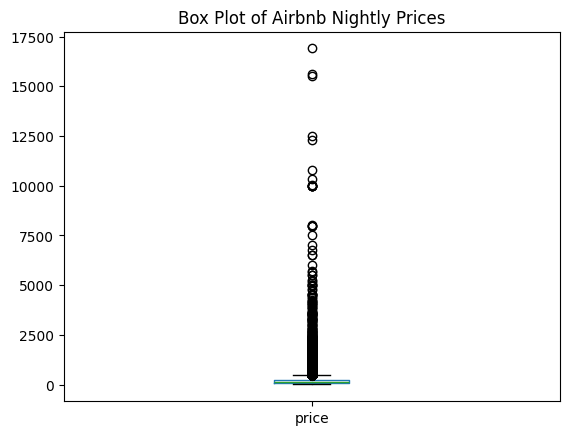

In [59]:
# price box plot
listings.boxplot(column="price", grid=False)
plt.suptitle("")
plt.title("Box Plot of Airbnb Nightly Prices")
plt.show()

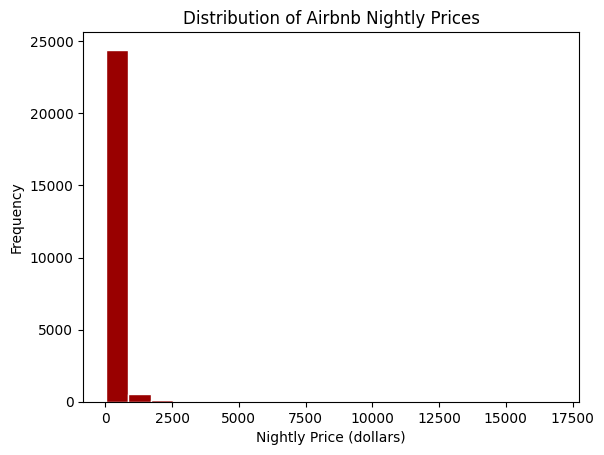

In [60]:
# price histogram
listings["price"].plot(kind="hist", bins=20, edgecolor="white", color="#990000")
plt.xlabel("Nightly Price (dollars)")
plt.title("Distribution of Airbnb Nightly Prices")
plt.show()

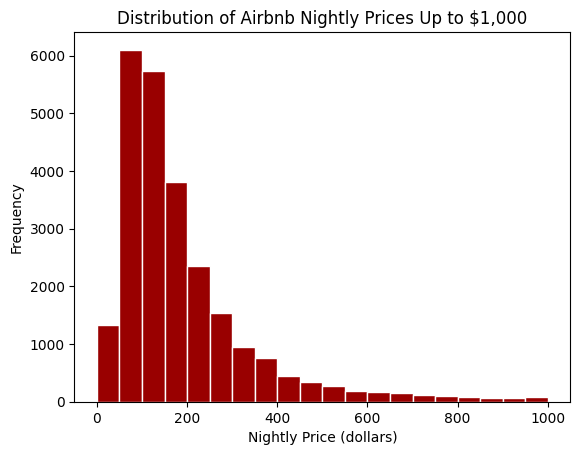

In [61]:
# histogram of prices up to $1,000
listings["price"].plot(kind="hist", bins=20, range=(0, 1000), edgecolor="white", color="#990000")
plt.xlabel("Nightly Price (dollars)")
plt.title("Distribution of Airbnb Nightly Prices Up to $1,000")
plt.show()

The histograms show that Airbnb nightly prices are heavily right skewed, which supports my hypothesis. In the first histogram, most listings are grouped into one bar because a few extremely expensive properties make the price range so large. I created a second histogram showing prices up to \\$1,000 to get a better look at how most listings are distributed. Most listings cost between \\$50 and \\$250 per night, with fewer listings as prices increase. The box plot also shows many high price outliers with the highest price reaching \\$16,903. Since the mean price of \\$231.60 is much higher than the median of\\ $144, the median gives a better idea of what a typical Airbnb listing costs in Los Angeles.

One implication is that if investors use the mean nightly price of \\$231.60 to estimate potential rental income may expect to charge more than what most listings actually charge. The median of \\$144 gives a better idea of a typical nightly price although it may not reflect what a particular property could charge. Prices can also vary depending on location and property type. Since this analysis combines private rooms and entire homes, the mean may not accurately represent the typical price within either category. This could lead to misleading estimates. Additionally, these are advertised prices, which don't tell us how often properties are booked or how much revenue they earn. We would need that information before estimating potential rental income.

#### Accommodates
Accommodates is a numerical variable that represents the maximum number of guests an Airbnb listing can accommodate. Higher values indicate that a property can host more people. The number of guests a listing can accommodate may depend on factors such as the property's size, number of bedrooms, number of beds, and room type. This variable is useful for understanding the types of rental properties available in Los Angeles and whether listings are generally suited for smaller or larger groups. It may also help explain differences in nightly prices since properties that accommodate more guests may have higher rental rates.

**Hypothesis**: I expect listings accommodating around 4 guests to be common, since this is a common capacity for families or small groups. I also expect many listings to accommodate 1-2 guests, with fewer properties available for much larger groups.

In [62]:
# accommodates descriptive statistics
descriptive_statistics("accommodates")

,mean,median,std,mode,range
accommodates,4.10,3.00,2.84,2,15


Airbnb listings in Los Angeles accommodate an average of 4.10 guests while the median is 3 and the most common capacity is 2 guests. The mean being higher than the median suggests that the distribution is right skewed with larger properties pulling the average up. The standard deviation is 2.84 guests and the range is 15 which shows that guest capacities vary considerably across listings. These results partially support my hypothesis. Although the average capacity is close to 4 guests, the mode of 2 shows that listings accommodating 2 guests are the most common.

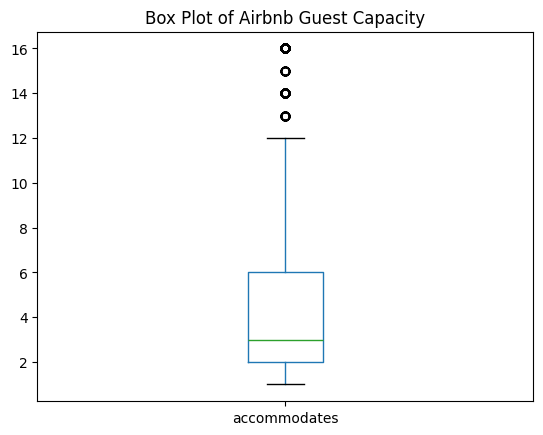

In [63]:
# accommodates box plot
listings.boxplot(column="accommodates", grid=False)
plt.suptitle("")
plt.title("Box Plot of Airbnb Guest Capacity")
plt.show()

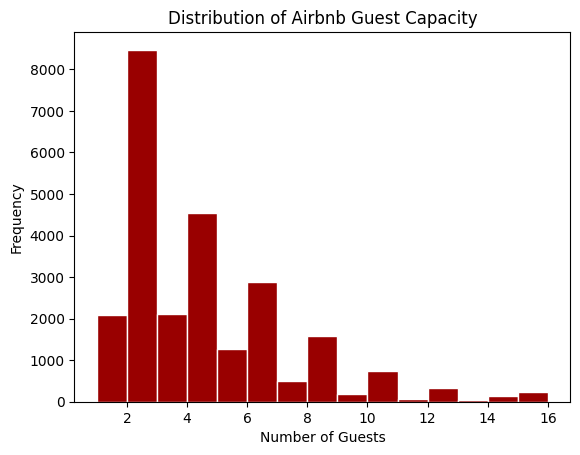

In [64]:
# accommodates histogram
listings["accommodates"].plot(kind="hist", bins=15, edgecolor="white", color="#990000")
plt.xlabel("Number of Guests")
plt.title("Distribution of Airbnb Guest Capacity")
plt.show()

The distribution of Airbnb guest capacity is right skewed with most listings accommodating between 2 and 6 guests. The histogram shows that 2 guests is the most common capacity, followed by 4 guests. This partially supports my hypothesis, although listings accommodating 2 guests are more common than those accommodating 4 guests. The The box plot shows that the middle 50% of listings accommodate between 2 and 6 guests while properties accommodating 13-16 guests appear as outliers. These larger capacities are reasonable for properties designed to host big groups.

One implication of these findings is that guests traveling in larger groups may have fewer Airbnb properties to choose from since most listings accommodate between 2 and 6 guests. However, this does not necessarily mean that smaller groups are more common among Airbnb travelers since the data only shows how many guests each property can accommodate. Another concern is that guest capacity is reported by hosts and may not accurately reflect how comfortably a property can accommodate that many people. There is also a potential risk of selection bias because we removed some rows with missing information during data cleaning. If larger properties were more likely to have missing values they could be underrepresented in the remaining dataset, making smaller capacities appear more common than they are in reality.

#### Bedrooms
Bedrooms is a numerical variable that represents the number of bedrooms in an Airbnb listing. This helps describe the size of a rental and how much sleeping space it offers. The number of bedrooms may vary depending on the property type, with entire homes generally having more bedrooms than private rooms or studio apartments. This variable may also be related to guest capacity and nightly price since properties with more bedrooms can often accommodate larger groups and may charge higher rates.

**Hypothesis**: Based on the accommodates analysis, where most listings accommodate between 2 and 6 guests, I expect most Airbnb listings to have 1-2 bedrooms, since that would generally provide enough sleeping space for this number of people. I expect fewer listings to have 3 bedrooms and even fewer to have 4 or more.

In [65]:
# bedrooms descriptive statistics
descriptive_statistics("bedrooms")

,mean,median,std,mode,range
bedrooms,1.70,1.00,1.24,1.00,12.00


Airbnb listings in Los Angeles have an average of 1.70 bedrooms and both the median and mode are 1 bedroom. This suggests that one bedroom listings are very common. The mean being higher than the median also suggests that the distribution is right skewed with properties containing more bedrooms pulling the average upward. The standard deviation is 1.24 bedrooms and the range is 12, indicating that some listings have substantially more bedrooms than others.

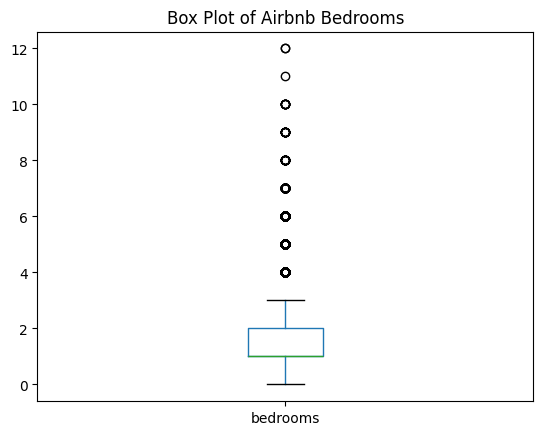

In [66]:
# bedrooms box plot
listings.boxplot(column="bedrooms", grid=False)
plt.suptitle("")
plt.title("Box Plot of Airbnb Bedrooms")
plt.show()

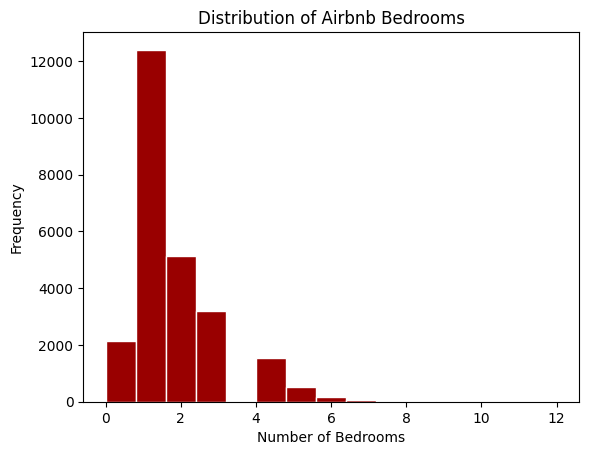

In [67]:
# bedrooms histogram
listings["bedrooms"].plot(kind="hist", bins=15, edgecolor="white", color="#990000")
plt.xlabel("Number of Bedrooms")
plt.title("Distribution of Airbnb Bedrooms")
plt.show()

The histogram shows that 1 bedroom listings are the most common in Los Angeles, followed by 2 bedroom and 3 bedroom properties. The number of listings generally decreases as the bedroom count increases with relatively few properties having 5 or more bedrooms. This supports my hypothesis that most listings would have 1-2 bedrooms. The box plot also shows that the middle 50% of listings have between 1 and 2 bedrooms with properties containing 4 or more bedrooms appearing as outliers.

These findings are consistent with the earlier accommodates analysis, where most listings accommodated between 2 and 6 guests. This suggests that smaller properties make up a large portion of Airbnb listings in Los Angeles. However, the number of bedrooms alone does not tell us how many guests a property can accommodate, since some listings may have multiple beds in one room. Further analysis could examine whether properties with more bedrooms tend to have higher nightly prices and accommodate more guests.

One implication of these findings is that the Airbnb market in Los Angeles has more listings with fewer bedrooms which may make it difficult for guests traveling in large groups to find rentals with more sleeping spaces. It may also influence how hosts evaluate their properties, since bedroom count can affect the types of guests they can accommodate and the nightly prices they can charge. However, room type is a potential confounding variable when comparing bedroom counts and prices, since private rooms and entire homes may differ in size and pricing. Another concern is that bedroom counts are reported by hosts, so inaccurate or inconsistent information could affect the reliability of the results. Comparing bedroom counts across room types would help determine whether the distribution reflects similar patterns within each category.

#### Bathrooms
Bathrooms is a numerical variable that represents the number of bathrooms available in an Airbnb listing. This can include half bathrooms, which is why some values may be decimals. The number of bathrooms can affect how appealing a listing is for guests, especially when multiple people are staying together. Listings with more bathrooms may sometimes also have higher nightly prices.

**Hypothesis**: Based on the earlier analyses showing that most listings have 1-2 bedrooms and accommodate 2-6 guests, I expect most Airbnb listings to have 1 bathroom. I expect relatively few listings to have 3 or more bathrooms. 

In [68]:
# bathrooms descriptive statistics
descriptive_statistics("bathrooms")

,mean,median,std,mode,range
bathrooms,1.56,1.00,1.04,1.00,12.00


The mean number of bathrooms is 1.56 while both the median and mode are 1 bathroom. This supports my hypothesis that listings with 1 bathroom would be the most common. The standard deviation is 1.04, and the range is 12 bathrooms, showing that some listings have considerably more bathrooms than others. Since the mean is higher than the median, the distribution may be right skewed with a smaller number of listings having many bathrooms.

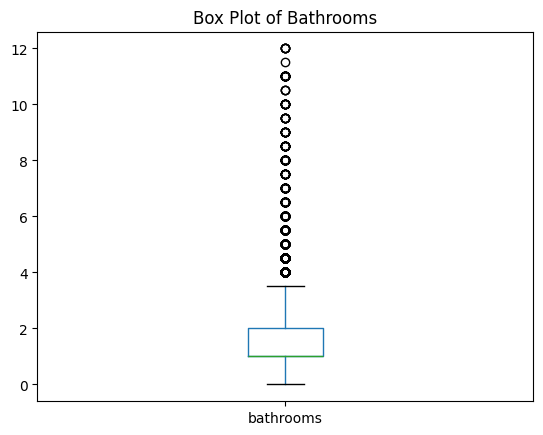

In [69]:
# bathrooms box plot
listings.boxplot(column="bathrooms", grid=False)
plt.suptitle("")
plt.title("Box Plot of Bathrooms")
plt.show()

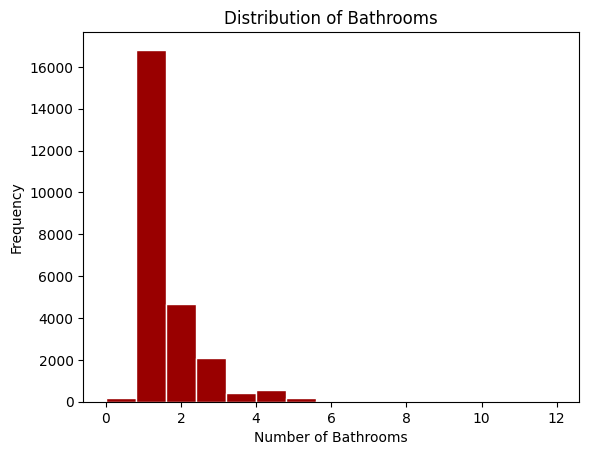

In [70]:
# bathrooms histogram
listings["bathrooms"].plot(kind="hist", bins=15, edgecolor="white", color="#990000")
plt.xlabel("Number of Bathrooms")
plt.title("Distribution of Bathrooms")
plt.show()

Th histogram shows that most Airbnb listings have 1 bathroom. The number of listings decreases as the bathroom count increases with relatively few listings having 3 or more. This supports my hypothesis that 1 bathroom would be the most common. The distribution is right skewed which is consistent with the mean of 1.56 being higher than the median of 1.

The box plot shows that the middle 50% of listings have between 1 and 2 bathrooms, with several outliers above 3.5 bathrooms extending up to 12. These higher values may belong to larger properties, although we would need to examine the listings more closely to confirm this. Since the distribution is right skewed, relying on the mean alone could give a misleading impression of a typical listing. The median of 1 bathroom better represents what guests are most likely to find.

One implication of these findings is that the bathroom count of a typical Airbnb listing may not reflect the needs of every type of property. Although most listings have 1 bathroom, investors should be careful about using this as a benchmark for properties of different sizes. Additionally, selection bias could affect these findings because listings with missing bathroom information were removed during data cleaning. If those listings had different bathroom counts from the retained listings, the distribution may not accurately represent the full Los Angeles Airbnb market.

#### Beds
Beds is a numerical variable that represents the number of beds available in an Airbnb listing. This helps show how much sleeping space a property offers and how many guests it may be able to accommodate. The number of beds may also be related to nightly price, since listings with more beds can accommodate larger groups and therefore be priced higher.

**Hypothesis**: Based on the earlier analyses, I expect most listings to have 1 or 2 beds. I also expect listings with 3 or more beds to become less common as the number increases.

In [71]:
# beds descriptive statistics
descriptive_statistics("beds")

,mean,median,std,mode,range
beds,2.23,2.00,1.67,1.00,25.00


The mean number of beds is 2.23, while the median is 2 and the mode is 1. The standard deviation is 1.67, and the range is 25 beds, suggesting that some listings have considerably more beds than others. Since the mean is slightly higher than the median, the distribution may be right skewed.

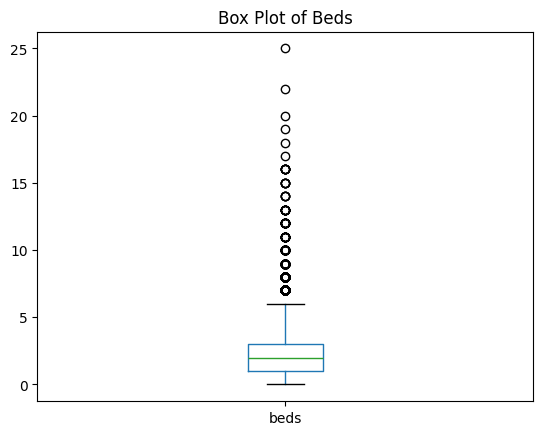

In [72]:
# beds box plot
listings.boxplot(column="beds", grid=False)
plt.suptitle("")
plt.title("Box Plot of Beds")
plt.show()

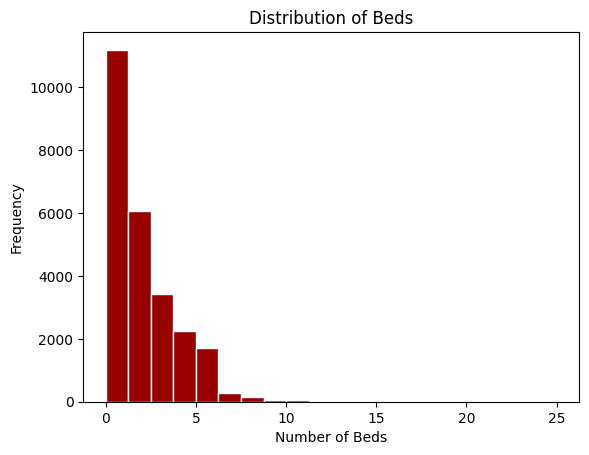

In [73]:
# beds histogram
listings["beds"].plot(kind="hist", bins=20, edgecolor="white", color="#990000")
plt.xlabel("Number of Beds")
plt.title("Distribution of Beds")
plt.show()

The histogram is right skewed with listings concentrated at lower bed counts and fewer listings as the number of beds increases. This supports my hypothesis that listings with 1 or 2 beds would be the most common. The mean is 2.23 beds, compared to a median of 2 and a mode of 1. The difference between these values suggests that listings with higher bed counts are pulling the mean upward.

The box plot shows that the middle 50% of listings have between 1 and 3 beds. There are outliers above 6 beds, reaching as high as 25. This suggests that most Airbnb listings offer relatively few beds, while properties with much larger sleeping capacities are less common. For guests traveling in large groups, this could mean fewer rental options to choose from. For hosts, it may be worth examining whether listings with more beds can charge higher nightly prices.

One implication of these findings is that investors looking for properties with many beds may have fewer comparable Airbnb listings to evaluate since most listings have between 1 and 3 beds. This could make it harder to determine whether a potential investment is priced competitively against similar properties. The analysis also has potential selection bias because listings with missing information were removed during data cleaning. If those listings tend to have different bed counts, the distribution may not accurately represent the full Los Angeles Airbnb market. Further analysis could examine whether bed count is associated with nightly price and whether this relationship differs across property types.

#### Minimum Nights
Minimum Nights is a numerical variable that represents the fewest nights a guest must book to reserve an Airbnb listing. Hosts set this requirement, and it can vary depending on the property and local rental regulations. This variable helps show whether listings are geared toward short visits or longer stays and can affect which properties guests are able to book.

**Hypothesis**: I expect most listings to have a minimum stay of 1 to 3 nights, with another noticeable concentration around 30 nights due to longer-term rentals and local restrictions.

In [74]:
# minimum nights descriptive statistics
descriptive_statistics("minimum_nights")

,mean,median,std,mode,range
minimum_nights,14.27,3.00,20.57,30,729


The mean minimum stay is 14.27 nights while the median is 3 nights and the mode is 30 nights. This suggests that although many listings allow shorter stays, 30 nights is the most common individual minimum requirement. The large difference between the mean and median suggests a right skewed distribution with longer minimum stays pulling the mean up. The standard deviation of 20.57 and range of 729 nights also show considerable variation between listings. These results are consistent with my hypothesis, although the histogram will help show whether there are separate concentrations around shorter stays and 30 nights.

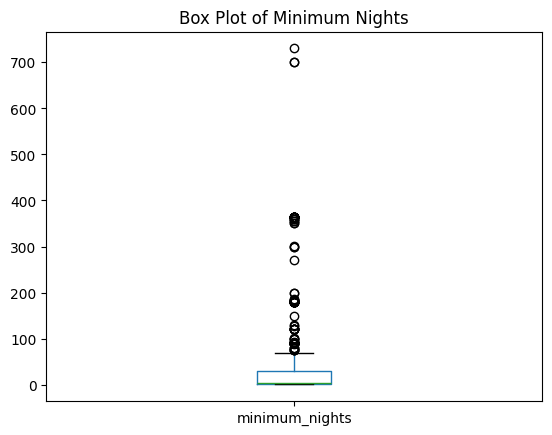

In [75]:
# minimum nights box plot
listings.boxplot(column="minimum_nights", grid=False)
plt.suptitle("")
plt.title("Box Plot of Minimum Nights")
plt.show()

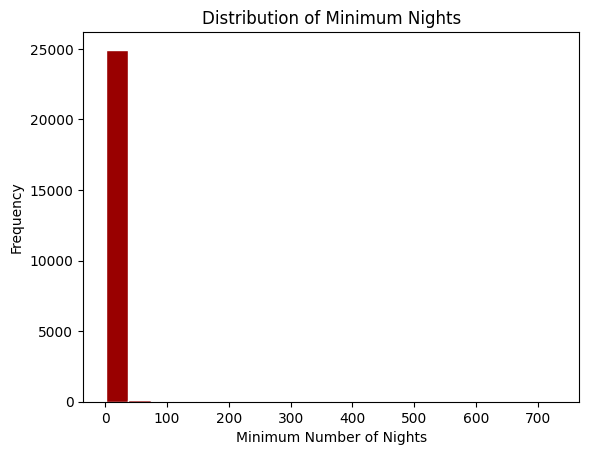

In [76]:
# minimum nights histogram
listings["minimum_nights"].plot(kind="hist", bins=20, edgecolor="white", color="#990000")
plt.xlabel("Minimum Number of Nights")
plt.title("Distribution of Minimum Nights")
plt.show()

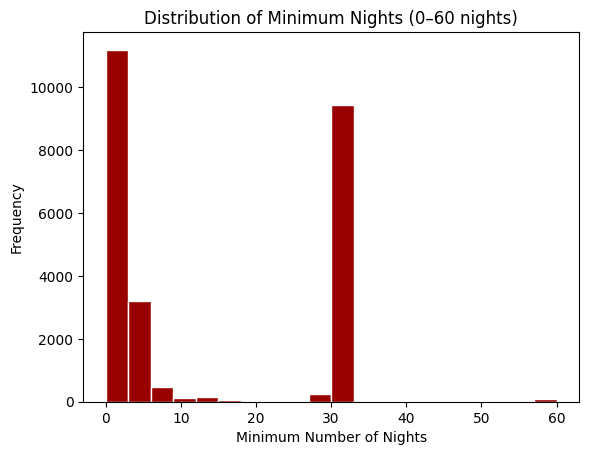

In [77]:
# minimum nights histogram (up to 60 nights)
listings["minimum_nights"].plot(kind="hist", bins=20, range=(0, 60), edgecolor="white", color="#990000")
plt.xlabel("Minimum Number of Nights")
plt.title("Distribution of Minimum Nights (0–60 nights)")
plt.show()

The first histogram shows a heavily right skewed distribution. Most listings are concentrated at lower minimum stay requirements. However, because some listings require more than 700 nights, it's difficult to see the differences between shorter stays. I created a second histogram showing only 0 to 60 nights to get a better understanding of the distribution. It shows two clear peaks, one around 1 to 3 nights and another around 30 nights, which supports my hypothesis.

The mean minimum stay is 14.27 nights, compared to a median of 3 and a mode of 30. This suggests that many listings allow short stays, while 30 nights is the most common individual requirement. The box plot shows several outliers with the highest values reaching approximately 730 nights. These may be listings intended for longer-term rentals, although some could also be potential data errors. The large standard deviation of 20.57 further shows how much minimum stay requirements vary between listings.

One implication is that the dataset only includes Airbnb listings as of March 2025. Minimum stay requirements may change over time due to local regulations or hosts adjusting their rental policies, so these results may not represent the market in other periods. It would also be misleading to assume that the two peaks reflect guests' preferred stay lengths, since the data only shows what hosts require. Looking at listings from different months and actual booking patterns would help determine whether these trends are consistent over time.

#### Number of Reviews
Number of Reviews is a numerical variable that represents the total number of guest reviews an Airbnb listing has received. It can help show how much feedback a property has accumulated over time. Listings with more reviews may have been available longer or received more bookings, although the review count does not tell us exactly how many guests have stayed there.

**Hypothesis**: I expect most listings to have relatively few reviews, with a smaller number having hundreds of reviews. I predict the distribution will be right skewed since some listings may have been active for much longer than others.

In [78]:
# number of reviews descriptive statistics
descriptive_statistics("number_of_reviews")

,mean,median,std,mode,range
number_of_reviews,56.60,18.00,98.28,1,3060


The mean number of reviews is 56.60 while the median is 18 and the mode is 1. The large difference between the mean and median suggests that there is a righ skewed distribution with listings that have many reviews pulling the mean up. The standard deviation is 98.28 and the range is 3,060 reviews which shows that there is a lot of variation between listings.

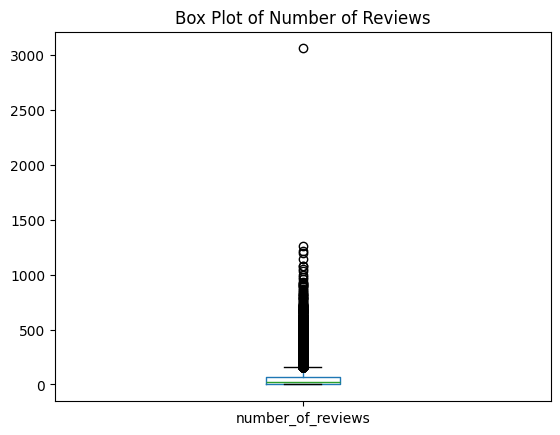

In [79]:
# number of reviews box plot
listings.boxplot(column="number_of_reviews", grid=False)
plt.suptitle("")
plt.title("Box Plot of Number of Reviews")
plt.show()

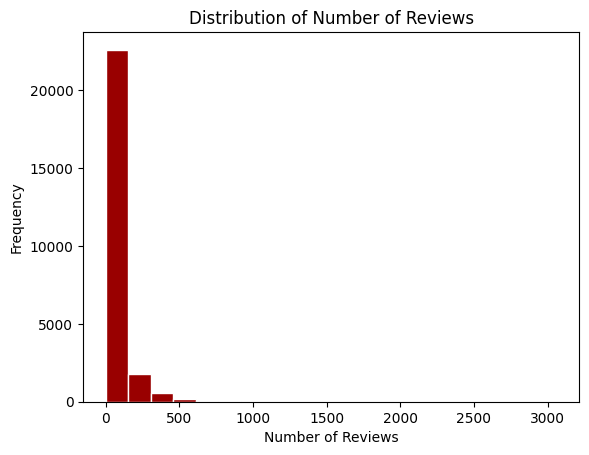

In [80]:
# number of reviews histogram
listings["number_of_reviews"].plot(kind="hist", bins=20, edgecolor="white", color="#990000")
plt.xlabel("Number of Reviews")
plt.title("Distribution of Number of Reviews")
plt.show()

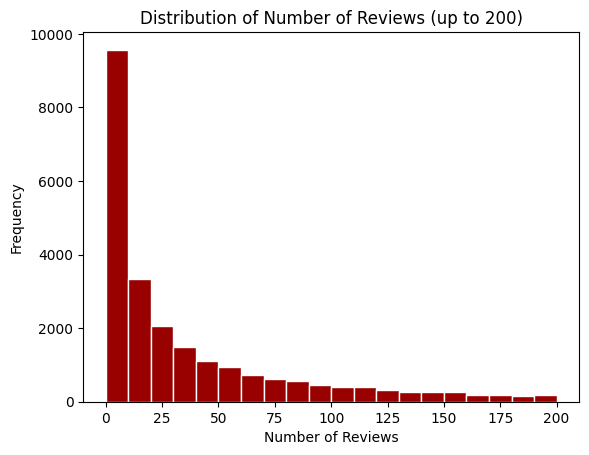

In [81]:
# number of reviews histogram (up to 200 reviews)
listings["number_of_reviews"].plot(kind="hist", bins=20, range=(0, 200), edgecolor="white", color="#990000")
plt.xlabel("Number of Reviews")
plt.title("Distribution of Number of Reviews (up to 200)")
plt.show()

The first histogram shows a heavily right skewed distribution. Most listings having relatively few reviews. Since the review counts extend beyond 3,000, I created a second histogram focusing on on 0 to 200 reviews to see the distribution more clearly. It shows that listings with 0 to 10 reviews are the most common, with fewer listings as the number of reviews increases. This supports my hypothesis that most listings would have relatively few reviews.

The mean number of reviews is 56.60, compared to a median of 18 and a mode of 1. The higher mean reflects the influence of listings with unusually large review counts. The box plot shows many high outliers, including one listing with over 3,000 reviews. This suggests that while some properties have accumulated a large amount of feedback most have received far fewer reviews. For guests, this means the amount of feedback available when evaluating a property can vary considerably.

One implication is that review counts don't necessarily reflect how popular or successful a listing is. The number of reviews can depend on how long a property has been listed and how often guests choose to leave reviews. For example, a newer listing may have fewer reviews simply because it has been available for a shorter time. This creates a potential confounding issue when comparing review counts since listing age can affect the number of reviews independently of how well a property performs. Assuming that listings with more reviews are automatically more popular or higher quality could lead to misleading conclusions. 

#### Review Scores Rating
Review Scores Rating is a numerical variable that represents the overall rating guests have given an Airbnb listing, on a scale from 1 to 5. Higher scores generally indicate more positive guest experiences, while lower scores may suggest dissatisfaction with some aspects of the stay. This variable helps show how satisfied guests are with a property and can influence how potential guests evaluate listings before booking. However, ratings are based on guests who choose to leave reviews so they may not reflect the experiences of everyone who has stayed at the property.

**Hypothesis**: I expect most listings to have ratings between 4 and 5, with relatively few receiving low ratings. I predict the distribution will be left skewed.

In [82]:
# review scores rating descriptive statistics
descriptive_statistics("review_scores_rating")

,mean,median,std,mode,range
review_scores_rating,4.79,4.91,0.40,5.00,4.00


In [83]:
# check how many listings have a recorded rating
listings["review_scores_rating"].agg(["count", "size"])

count    25188
size     25188
Name: review_scores_rating, dtype: int64

The mean review rating is 4.79 out of 5. The median is 4.91 and the mode is 5.00. These values suggest that most listings receive high ratings, which supports my hypothesis. Since the mean is lower than the median, the distribution may be left skewed with lower ratings pulling the mean down. The standard deviation of 0.40 shows that ratings are generally concentrated near the higher end of the scale. However, the range of 4.00 indicates that some listings have much lower ratings than others.

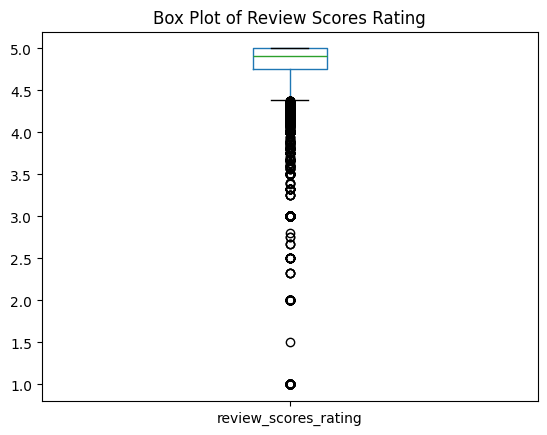

In [84]:
# review scores rating box plot
listings.boxplot(column="review_scores_rating", grid=False)
plt.suptitle("")
plt.title("Box Plot of Review Scores Rating")
plt.show()

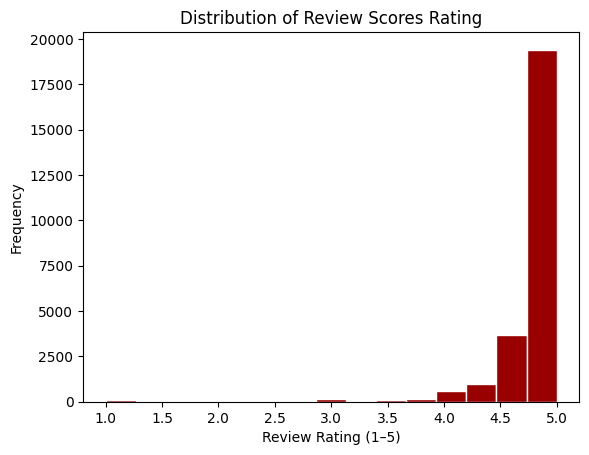

In [85]:
# review scores rating histogram
listings["review_scores_rating"].plot(kind="hist", bins=15, edgecolor="white", color="#990000")
plt.xlabel("Review Rating (1–5)")
plt.title("Distribution of Review Scores Rating")
plt.show()

The histogram shows a left skewed distribution with most Airbnb listings receiving ratings close to 5 and relatively few receiving low ratings. This supports my hypothesis that ratings would generally fall between 4 and 5. The box plot shows that the middle 50% of ratings fall approximately between 4.75 and 5.00, with a median of 4.91. There are several outliers below approximately 4.4, including ratings as low as 1. The standard deviation of 0.40 indicates that most ratings are fairly close together despite these lower values. These results suggest that highly rated properties are common in the dataset, which could make it harder for guests to distinguish between listings based on ratings alone.

One implication of these findings is that investors could overestimate a property's quality if they rely too heavily on its average review rating. Listings with only a few reviews may have high ratings that don't accurately reflect guest experiences over time. There is also a risk of sampling bias since ratings only come from guests who choose to leave reviews. Guests with extremely positive or negative experiences may typically be more likely to leave reviews, meaning the ratings may not represent everyone who stayed at the property.

#### Host Is Superhost
Host Is Superhost is a categorical variable that indicates whether an Airbnb host has earned Superhost status. Hosts qualify by meeting Airbnb's requirements for guest ratings, response rates, cancellations, and completed reservations. Superhost status appears as a badge on a host's profile and listings which may influence guests when choosing where to stay. In this dataset, 1 represents a Superhost and 0 represents a non-Superhost.

**Hypothesis**: I expect non-Superhosts to make up a larger share of listings than Superhosts since hosts must meet specific requirements to earn this status.

In [86]:
# host is superhost counts
listings["host_is_superhost"].value_counts(sort=False)

host_is_superhost
0.00    12195
1.00    12993
Name: count, dtype: int64

In [87]:
# host is superhost percentages
listings["host_is_superhost"].value_counts(normalize=True).mul(100).round(2)

host_is_superhost
1.00   51.58
0.00   48.42
Name: proportion, dtype: float64

The results show that 12,993 listings are hosted by Superhosts compared to 12,195 listings hosted by non-Superhosts. The listings are fairly evenly split between the two categories, with slightly more hosted by Superhosts. This goes against my hypothesis that non-Superhosts would make up a larger share of listings.

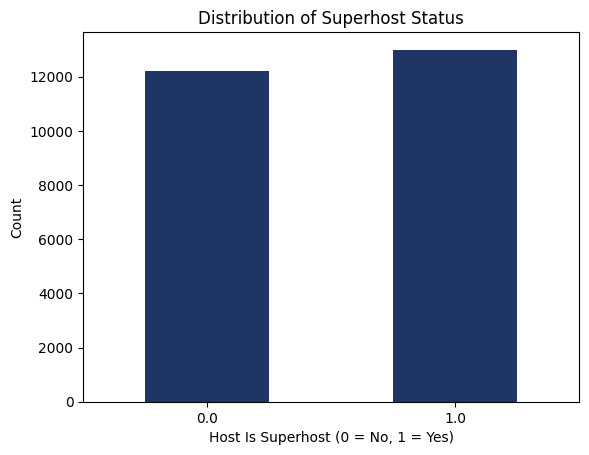

In [88]:
# bar chart of host is superhost counts
listings["host_is_superhost"].value_counts(sort=False).plot(kind="bar", color="#1F3564", rot=0)
plt.xlabel("Host Is Superhost (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.title("Distribution of Superhost Status")
plt.show()

The bar chart shows that Superhosts account for slightly more listings than non-Superhosts. The difference is very small though, so the two groups are represented fairly evenly in the dataset. This goes against my hypothesis that non-Superhosts would be more common.

One implication is that the dataset counts listings rather than individual hosts. A host that is managing multiple properties would appear several times, which could make Superhost status seem more common than it is among individual hosts. The chart also combines all listings across LA, which could hide differences between neighbourhoods or room types. Comparing Superhost and non-Superhost listings within these groups could show whether the overall pattern holds across different types of rentals.

#### Instant Bookable

Instant Bookable is a categorical variable that indicates whether an Airbnb listing can be booked immediately without requiring the host to approve the reservation. A value of 0 represents listings that do not allow instant booking, while 1 represents listings that do. This variable helps show how common instant booking is among LA Airbnb listings and whether guests can reserve a property directly or need to wait for host approval.

**Hypothesis**: I expect most of the listings to allow instant booking although a large number may still require host approval.

In [89]:
# instant bookable counts
listings["instant_bookable"].value_counts(sort=False)

instant_bookable
0    18826
1     6362
Name: count, dtype: int64

In [90]:
# instant bookable percentages
listings["instant_bookable"].value_counts(normalize=True).mul(100).round(2)

instant_bookable
0   74.74
1   25.26
Name: proportion, dtype: float64

The results show that 18,826 listings don't allow instant booking while 6,362 listings do. This goes against my hypothesis that most listings would allow instant booking. The difference suggests that most hosts in this dataset require guests to receive approval before confirming a reservation. 

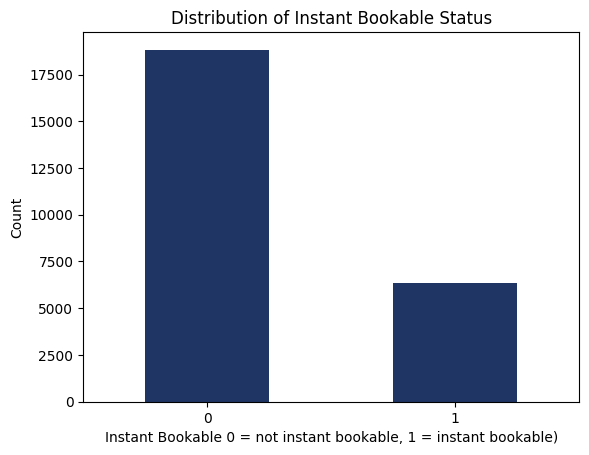

In [91]:
# bar chart of instant bookable counts
listings["instant_bookable"].value_counts(sort=False).plot(kind="bar", color="#1F3564", rot=0)
plt.xlabel("Instant Bookable 0 = not instant bookable, 1 = instant bookable)")
plt.ylabel("Count")
plt.title("Distribution of Instant Bookable Status")
plt.show()

The bar chart clearly shows that listings requiring host approval are much more common than listings that allow instant booking. This contradicts my hypothesis that most listings would allow guests to book immediately.  For an investment firm, this knowing this is useful because the booking process could affect how easily guests can secure a reservation and how much time hosts spend managing booking requests. Investors could explore whether offering instant booking is associated with differences in listing performance before deciding whether to include it in their property management strategy.

One implication is that the dataset only shows whether instant booking is enabled. It doesn't include enough information to determine whether this setting affects occupancy rates or rental income. This matters for investment decisions because a booking feature may be common without necessarily improving a property's financial performance. Examining occupancy and revenue alongside instant booking status can help determine whether the feature is associated with stronger rental performance.

#### Neighbourhood Cleansed

Neighbourhood cleansed is a categorical variable that identifies the neighbourhood where each Airbnb listing is located in Los Angeles. This allows us to examine how Airbnb listings are distributed across different neighbourhoods. Location is an important factor especially in the short-term rental market because guests may prefer properties that are close to popular attractions. Neighbourhoods with greater tourist demand may attract more Airbnb hosts, which could lead to a higher concentration of listings. Location may also influence nightly prices, since guests may be willing to pay more to stay in desirable areas.

**Hypothesis:** I expect Airbnb listings to be unevenly distributed across neighbourhoods, with more listings in areas near popular tourist attractions and beaches. I expect neighbourhoods farther from these destinations to generally have fewer listings.

In [92]:
# neighbourhood counts
listings["neighbourhood_cleansed"].value_counts(sort=False)

neighbourhood_cleansed
Lakewood                    49
View Park-Windsor Hills    143
Silver Lake                309
Mid-Wilshire               249
West Los Angeles            97
                          ... 
Rancho Dominguez             1
Lopez/Kagel Canyons          4
Sun Village                  3
San Marino                   3
Val Verde                    1
Name: count, Length: 265, dtype: int64

In [93]:
# top 15 neighbourhoods
listings["neighbourhood_cleansed"].value_counts().head(15)

neighbourhood_cleansed
Long Beach              1238
Venice                   850
Hollywood                812
Santa Monica             790
West Hollywood           647
Downtown                 539
Beverly Hills            537
Alhambra                 486
Glendale                 474
Pasadena                 449
Hollywood Hills          430
Burbank                  407
Culver City              399
Rowland Heights          343
Hollywood Hills West     322
Name: count, dtype: int64

In [94]:
# top 15 neighbourhood relative frequencies
listings["neighbourhood_cleansed"].value_counts(normalize=True).head(15)

neighbourhood_cleansed
Long Beach             0.05
Venice                 0.03
Hollywood              0.03
Santa Monica           0.03
West Hollywood         0.03
Downtown               0.02
Beverly Hills          0.02
Alhambra               0.02
Glendale               0.02
Pasadena               0.02
Hollywood Hills        0.02
Burbank                0.02
Culver City            0.02
Rowland Heights        0.01
Hollywood Hills West   0.01
Name: proportion, dtype: float64

The dataset contains 265 unique neighbourhoods and the Airbnb listings are distributed unevenly across Los Angeles. Long Beach has the highest number of listings at 1,238, accounting for approximately 5% of all listings in the dataset. Venice has 850 listings, Hollywood has 812, and Santa Monica has 790, each accounting for approximately 3% of the total. Some neighbourhoods have only one or a few listings. This suggests that Airbnb activity is concentrated in certain areas, although no single neighborhood accounts for a large share of the overall dataset.

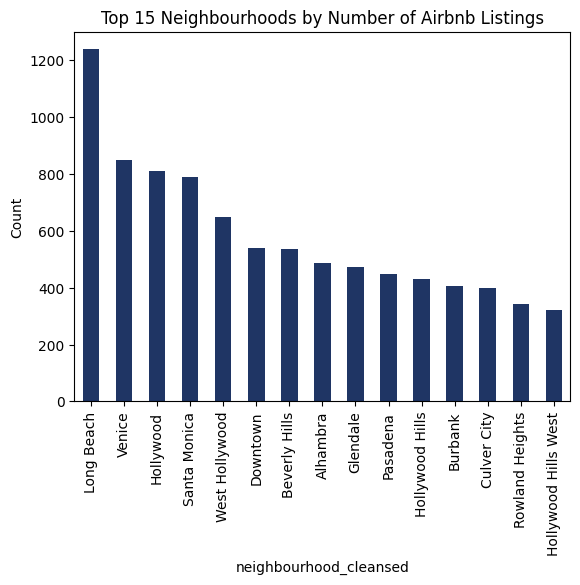

In [95]:
# bar chart of top 15 neighbourhood counts
listings["neighbourhood_cleansed"].value_counts().head(15).plot(kind="bar", color="#1F3564", rot=90)
plt.ylabel("Count")
plt.title("Top 15 Neighbourhoods by Number of Airbnb Listings")
plt.show()

The bar chart shows that Airbnb listings are unevenly distributed across neighbourhoods. Long Beach has the most listings at 1,238, followed by Venice with 850 and Hollywood with 812. Several neighbourhoods with high listing counts, including Venice and Santa Monica, are close to popular beaches, while Hollywood attracts visitors because of its tourist attractions. These findings generally support my hypothesis that neighbourhoods near popular destinations would have more Airbnb listings. However, neighboruhoods such as Alhambra and Glendale also have relatively high counts, suggesting that other factors may influence where Airbnb hosts choose to list their properties.

One implication is that the chart only shows the 15 neighbourhoods with the most listings, which could introduce selection bias if we use these results to draw conclusions about all 265 neighbourhoods. Another concern is that having more Airbnb listings does not necessarily mean a neighbourhood is more popular with tourists, since we don't know how often these properties are booked. Neighbourhood size and housing availability could also be confounding variables, as some areas may have more listings simply because they have more properties available for rent. Without considering these factors, we could overestimate the role of tourist demand in explaining why certain neighbourhoods have more Airbnb listings.

#### Neighbourhood Group Cleansed

Neighbourhood group cleansed is a categorical variable that identifies the broader geographic area where each Airbnb listing is located within Los Angeles County. The dataset groups listings into three categories based on their location. City of Los Angeles refers to listings within the city's boundaries, while Other Cities includes listings in surrounding cities such as Santa Monica and Long Beach. Unincorporated Areas are communities that are part of Los Angeles County but are not governed by an individual city. These geographic differences are important because local governments can have different rules for rentals, which may affect how many Airbnb properties are available in each area. The number of listings may also depend on the availability of housing and how attractive an area is to visitors.

**Hypothesis:** I expect the City of Los Angeles to have the most Airbnb listings because it covers a large area with many popular tourist destinations. I expect Unincorporated Areas to have the fewest listings because they generally have fewer densely populated urban areas.

In [96]:
# neighbourhood group counts
listings["neighbourhood_group_cleansed"].value_counts()

neighbourhood_group_cleansed
Other Cities            11327
City of Los Angeles     11084
Unincorporated Areas     2777
Name: count, dtype: int64

In [97]:
# neighbourhood group relative frequencies
listings["neighbourhood_group_cleansed"].value_counts(normalize=True)

neighbourhood_group_cleansed
Other Cities           0.45
City of Los Angeles    0.44
Unincorporated Areas   0.11
Name: proportion, dtype: float64

The dataset contains three neighbourhood groups. Other Cities has the most Airbnb listings at 11,327, accounting for approximately 45% of the dataset. The City of Los Angeles follows closely with 11,084 listings which is 44% of the data set. Unincorporated Areas has the fewest at 2,777 listings which is 11% of the dataset. These results partially support my hypothesis. Although I expected the City of Los Angeles to have the most listings, Other Cities has a slightly higher count. However, Unincorporated Areas has the fewest listings as I expected.

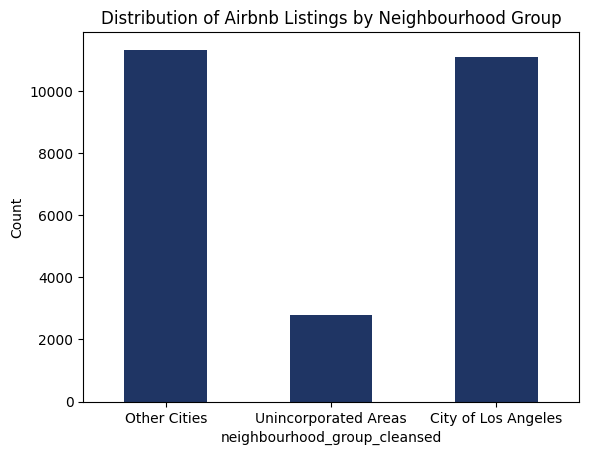

In [98]:
# bar chart of neighbourhood group counts
listings["neighbourhood_group_cleansed"].value_counts(sort=False).plot(kind="bar", color="#1F3564", rot=0)
plt.ylabel("Count")
plt.title("Distribution of Airbnb Listings by Neighbourhood Group")
plt.show()

The bar chart shows that Airbnb listings are distributed unevenly across the three neighbourhood groups. Other Cities has slightly more listings than the City of Los Angeles, although the difference is only 243 listings. This was somewhat unexpected because I initially assumed the City of Los Angeles would have the most listings due to its tourist attractions. However, Other Cities includes multiple popular destinations, such as Santa Monica and Long Beach, which may help explain its high listing count. On the other hand, Unincorporated Areas have significantly fewer listings.

One implication is that the three neighbourhood groups represent different numbers of cities and communities, which makes their listing counts difficult to compare directly. Since Other Cities combines listings from multiple cities, its total may hide differences between individual locations. This could lead investors to misjudge where Airbnb listings are most concentrated. There is also a risk of overlooked confounding variables, such as housing availability and local rental regulations, which can influence how many listings are in each area. Therefore, a higher listing count doesn't necessarily mean greater tourist demand. Looking at individual cities could help investors better understand these differences.

#### Room Type
Room type is a categorical variable that identifies the type of space guests can book through Airbnb. The dataset includes four categories: Entire home/apt, Private room, Shared room, and Hotel room. An entire home/apartment gives guests access to the full property, while a private room provides a separate bedroom within a property that may have shared common areas. Shared rooms involve sharing sleeping space with other guests, and hotel rooms are accommodations offered in hotel style properties. Room type is important because it affects the level of privacy and space guests receive, which may influence demand and nightly rental prices. Guests looking for more privacy may prefer entire homes, while those traveling on a budget may choose private or shared rooms.

**Hypothesis:** I expect Entire home/apt to be the most common room type because it provides guests with greater privacy during their stay. I expect Shared room to be the least common because guests may prefer having their own sleeping space.

In [99]:
# room type counts
listings["room_type"].value_counts()

room_type
Entire home/apt    19311
Private room        5697
Shared room           99
Hotel room            81
Name: count, dtype: int64

In [100]:
# room type relative frequencies
listings["room_type"].value_counts(normalize=True)

room_type
Entire home/apt   0.77
Private room      0.23
Shared room       0.00
Hotel room        0.00
Name: proportion, dtype: float64

Out of the 4 room types, Entire home/apt is the most common at 19,311 listings which is approximately 77% of the dataset. Private rooms are the second most common with 5,697 listings which is 23% of the dataset. Shared rooms and hotel rooms are much less common, with only 99 and 81 listings, respectively, each accounting for less than 1% of the total. 

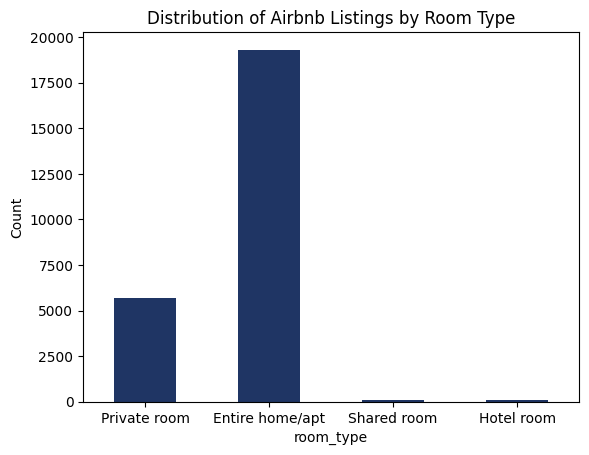

In [101]:
# bar chart of room type counts
listings["room_type"].value_counts(sort=False).plot(kind="bar", color="#1F3564", rot=0)
plt.ylabel("Count")
plt.title("Distribution of Airbnb Listings by Room Type")
plt.show()

The bar chart shows that entire homes and apartments make up the majority of Airbnb listings with 19,311 listings compared to 5,697 private rooms. This supports my hypothesis that entire homes would be the most common room type. One possible explanation is that guests may prefer having more privacy and space during their stay. Shared rooms and hotel rooms make up a very small portion of the dataset, although hotel rooms are slightly less common than shared rooms, which was unexpected. The large number of entire home listings could also affect the distribution of nightly prices, since entire properties may charge more than individual rooms. It would be useful to compare prices across room types to see whether this pattern holds in the dataset.

One implication of these findings is that the high number of entire homes and apartments could affect overall Airbnb prices since renting an entire property is generally more expensive than renting a single room. This may also mean that guests looking for more affordable accommodations have fewer options. For hosts, the large number of entire home listings could mean more competition when trying to attract guests. However, having more listings does not necessarily mean that guests prefer this room type, since the data only shows how many properties are listed. Property size and location could also be confounding variables when comparing prices, as larger properties and those in more expensive neighbourhoods may charge higher rates. 

#### Property Type
Property type is a categorical variable that identifies the kind of accommodation offered in each Airbnb listing. It differs from room type because it describes whether the property is a house, apartment, hotel, or another type of accommodation, while room type indicates whether guests rent the entire space or share parts of it with others. Property type may influence nightly prices because different accommodations offer different amounts of space and amenities. 

**Hypothesis:** I expect entire homes and rental units to be the most common property types. I expect less common accommodations, like boats or tiny homes, to make up a small portion of listings because fewer of these properties are typically available.

In [102]:
# property type counts
listings["property_type"].value_counts()

property_type
Entire home                           7399
Entire rental unit                    5770
Private room in home                  3501
Entire guesthouse                     2033
Entire condo                          1082
Entire guest suite                     935
Private room in rental unit            756
Entire townhouse                       452
Entire villa                           372
Entire bungalow                        325
Room in hotel                          304
Private room in condo                  248
Private room in townhouse              244
Entire loft                            191
Entire serviced apartment              153
Private room in villa                  140
Private room in guest suite            130
Room in boutique hotel                 125
Entire cottage                         122
Tiny home                              120
Camper/RV                               88
Private room in bed and breakfast       80
Private room in bungalow                

In [103]:
# check property types with fewer than 30 listings
property_counts = listings["property_type"].value_counts()
property_counts[property_counts < 30]

property_type
Private room                          21
Private room in hostel                16
Farm stay                             16
Shared room in hostel                 15
Private room in loft                  12
Shared room in hotel                  11
Shared room in rental unit            11
Barn                                   9
Boat                                   8
Treehouse                              8
Private room in tiny home              8
Private room in casa particular        7
Shared room in guesthouse              7
Casa particular                        7
Private room in cabin                  6
Yurt                                   6
Room in serviced apartment             6
Castle                                 5
Tent                                   5
Private room in cottage                5
Earthen home                           5
Campsite                               4
Hut                                    4
Private room in farm stay              4
Sh

In [104]:
# top 15 property types
listings["property_type"].value_counts().head(15)

property_type
Entire home                    7399
Entire rental unit             5770
Private room in home           3501
Entire guesthouse              2033
Entire condo                   1082
Entire guest suite              935
Private room in rental unit     756
Entire townhouse                452
Entire villa                    372
Entire bungalow                 325
Room in hotel                   304
Private room in condo           248
Private room in townhouse       244
Entire loft                     191
Entire serviced apartment       153
Name: count, dtype: int64

In [105]:
# property type relative frequencies
listings["property_type"].value_counts(normalize=True).head(15)

property_type
Entire home                   0.29
Entire rental unit            0.23
Private room in home          0.14
Entire guesthouse             0.08
Entire condo                  0.04
Entire guest suite            0.04
Private room in rental unit   0.03
Entire townhouse              0.02
Entire villa                  0.01
Entire bungalow               0.01
Room in hotel                 0.01
Private room in condo         0.01
Private room in townhouse     0.01
Entire loft                   0.01
Entire serviced apartment     0.01
Name: proportion, dtype: float64

The most common property type is an entire home which has 7,399 listings, accounting for 29% of all listings. The second most common is Entire rental units with 5,770 listings, representing 23%, while private rooms in homes account for 3,501 listings and accounts for 14% of all listsing. These 3 property types make up approximately 66% of all listings. Less conventional accommodations are much less common, with only 8 boats, 8 treehouses, and 5 castles. This shows that Airbnb listings in Los Angeles are largely concentrated with traditional residential properties.

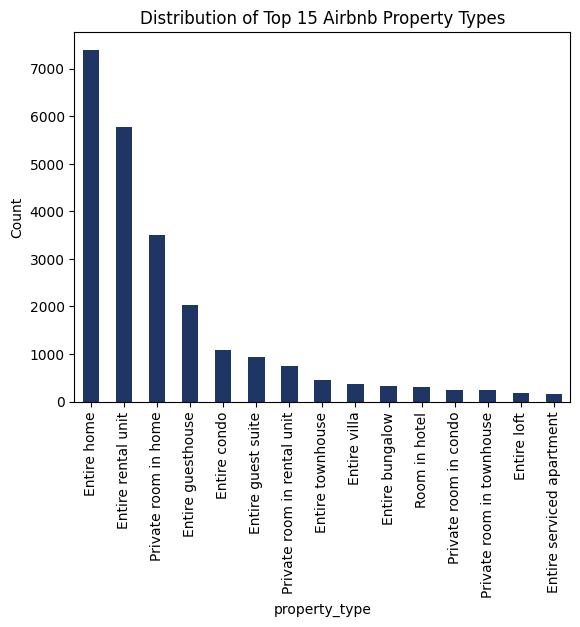

In [106]:
# bar chart of top 15 property type counts
listings["property_type"].value_counts().head(15).plot(kind="bar", color="#1F3564", rot=90)
plt.ylabel("Count")
plt.title("Distribution of Top 15 Airbnb Property Types")
plt.show()

The bar chart shows that entire homes and rental units are the most common property types in Los Angeles, which supports my hypothesis. Private rooms in homes are also common but the number of listings decreases sharply after the first few categories. This suggests that most Airbnb listings are traditional residential properties while accommodations such as boats and treehouses are much less common.

One implication of these findings is that hosts renting out entire homes or rental units may face more competition because there are many similar listings available. For guests, this means there are more options when searching for these types of properties. However, the number of listings doesn't tell us how often each property type is booked. Other factors, such as location and price, could influence guest choices, so we can't determine which property types are most popular based on listing counts alone.

### Bivariate Analysis

Bivariate analysis was conducted to examine relationships between nightly prices and listing characteristics, including property size, room type, location, and host attributes.

Scatterplots, boxplots, and correlation coefficients were used to identify patterns and compare pricing across different listing groups.

#### Price and Accommodates

I will examine the relationship between nightly price and the number of guests a listing accommodates to see whether properties with higher guest capacities tend to have higher prices and how strong this relationship is.

In [107]:
# correlation between accommodates and price
pearson = listings["accommodates"].corr(listings["price"], method="pearson")
spearman = listings["accommodates"].corr(listings["price"], method="spearman")

print("Pearson correlation:", round(pearson, 2))
print("Spearman correlation:", round(spearman, 2))

Pearson correlation: 0.39
Spearman correlation: 0.72


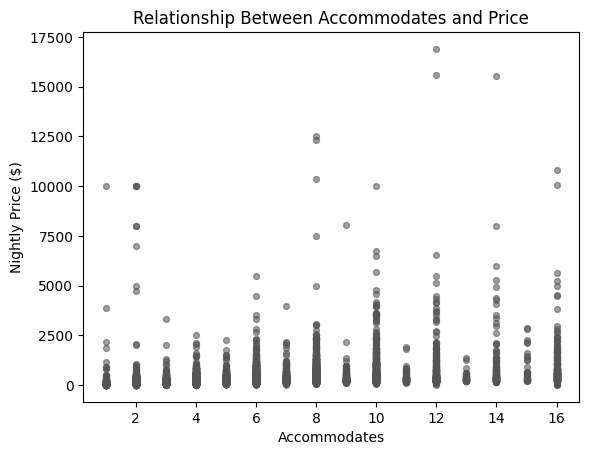

In [108]:
# scatterplot of price and accommodates
plt.scatter(listings["accommodates"], listings["price"], alpha=0.55, s=18, color="#555555")
plt.xlabel("Accommodates")
plt.ylabel("Nightly Price ($)")
plt.title("Relationship Between Accommodates and Price")
plt.show()

The relationship between accommodates and price is positive. The Pearson correlation is 0.39 and the Spearman correlation is 0.72 showing that listings that accommodate more guests generally have higher nightly prices. The scatterplot also shows that prices become more spread out as guest capacity increases, meaning that listings accommodating the same number of guests can still have very different prices. There are also some unusually high priced listings across different guest capacities. This suggests that guest capacity is an important factor in understanding nightly prices but it doesn't explain all of the variation in price. The differences between listings with similar guest capacities suggest that other property characteristics may also play a role in pricing. A useful next step would be to examine how bedrooms, bathrooms, and location relate to price.

#### Price and Bedrooms

I'm examining whether the number of bedrooms is related to nightly price since properties with more bedrooms may be priced differently.

In [109]:
# correlation between bedrooms and price
pearson = listings["bedrooms"].corr(listings["price"], method="pearson")
spearman = listings["bedrooms"].corr(listings["price"], method="spearman")

print("Pearson correlation:", round(pearson, 2))
print("Spearman correlation:", round(spearman, 2))

Pearson correlation: 0.43
Spearman correlation: 0.65


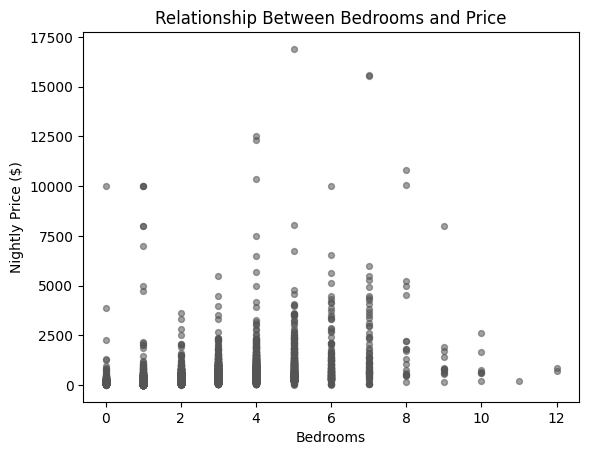

In [110]:
# scatterplot of price and bedrooms
plt.scatter(listings["bedrooms"], listings["price"], alpha=0.55, s=18, color="#555555")
plt.xlabel("Bedrooms")
plt.ylabel("Nightly Price ($)")
plt.title("Relationship Between Bedrooms and Price")
plt.show()

The number of bedrooms has a moderate positive relationship with nightly price, with a Pearson correlation of 0.43 and a Spearman correlation of 0.65. The higher Spearman correlation suggests that prices generally increase with bedroom count, although the relationship isn't perfectly linear. The scatterplot shows that listings with around 4 to 7 bedrooms include some of the highest nightly prices, but there are also expensive listings with only 1 or 2 bedrooms. This means that having more bedrooms doesn't always result in a higher price. For the real estate firm, this could mean that investing in larger properties may offer opportunities for higher nightly rates, but bedroom count alone may not be enough to determine a property's pricing potential. Location and property type could help explain some of these differences.

#### Price and Bathrooms

I'm examining whether listings with more bathrooms tend to have higher nightly prices and how much prices vary among properties with the same number of bathrooms.

In [111]:
# correlation between bathrooms and price
pearson = listings["bathrooms"].corr(listings["price"], method="pearson")
spearman = listings["bathrooms"].corr(listings["price"], method="spearman")

print("Pearson correlation:", round(pearson, 2))
print("Spearman correlation:", round(spearman, 2))

Pearson correlation: 0.5
Spearman correlation: 0.56


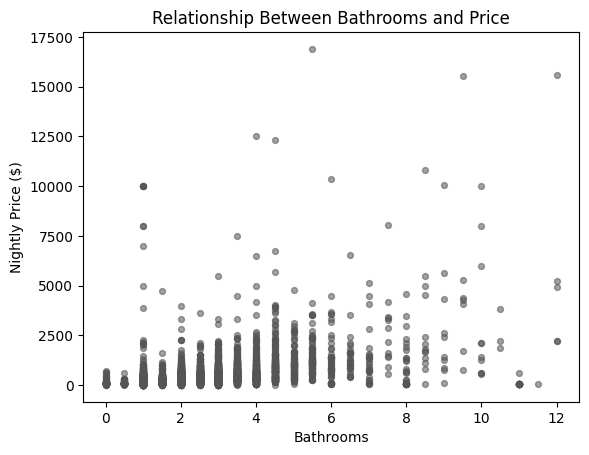

In [112]:
# scatterplot of price and bathrooms
plt.scatter(listings["bathrooms"], listings["price"], alpha=0.55, s=18, color="#555555")
plt.xlabel("Bathrooms")
plt.ylabel("Nightly Price ($)")
plt.title("Relationship Between Bathrooms and Price")
plt.show()

The relationship between bathrooms and price is moderately positive. The Pearson correlation is 0.50 and the Spearman correlation is 0.56, showing that listings with more bathrooms generally have higher nightly prices. The scatterplot shows that most listings with fewer bathrooms are concentrated at lower prices while properties with around 4 to 10 bathrooms have a wider range of prices. Some of the most expensive listings have 5 or more bathrooms, although there are also a few high priced listings with only 1 bathroom. This suggests that bathroom count may be an important consideration when evaluating properties, but adding more bathrooms would not necessarily lead to higher nightly prices. 

#### Price and Beds

I'm examining whether the number of beds in a listing is related to its nightly price and whether beds show a similar pricing pattern to bedrooms.

In [113]:
# correlation between beds and price
pearson = listings["beds"].corr(listings["price"], method="pearson")
spearman = listings["beds"].corr(listings["price"], method="spearman")

print("Pearson correlation:", round(pearson, 2))
print("Spearman correlation:", round(spearman, 2))

Pearson correlation: 0.34
Spearman correlation: 0.62


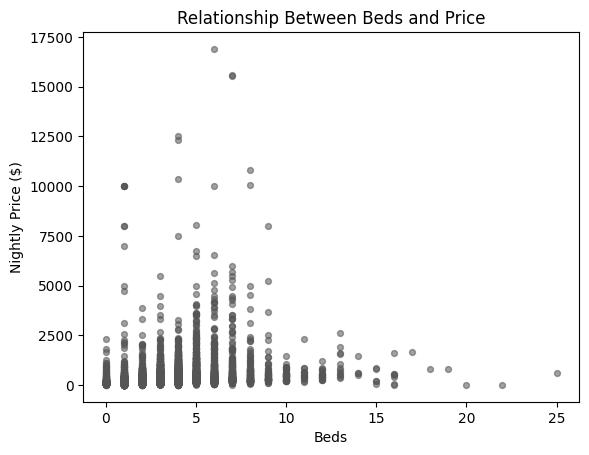

In [114]:
# scatterplot of price and beds
plt.scatter(listings["beds"], listings["price"], alpha=0.55, s=18, color="#555555")
plt.xlabel("Beds")
plt.ylabel("Nightly Price ($)")
plt.title("Relationship Between Beds and Price")
plt.show()

The relationship between beds and price is positive. The Pearson correlation is 0.34 while the Spearman correlation is 0.62. The difference between these values suggests that nightly prices generally increase with the number of beds but the relationship is not strongly linear. The scatterplot shows that some of the most expensive listings have around 4 to 8 beds while listings with 15 or more beds tend to have much lower prices. This suggests that having more beds does not necessarily mean a property can charge a higher nightly rate. Compared to bedrooms and bathrooms beds also have a weaker Pearson correlation with price. For the real estate firm, this could mean that the number of beds alone is less useful for evaluating a property's pricing potential. It may be worth examining how beds relate to guest capacity to better understand these differences.

#### Price and Minimum Nights

I'm examining whether listings that require longer minimum stays tend to have different nightly prices since minimum stay requirements could affect how properties are priced.

In [115]:
# correlation between minimum nights and price
pearson = listings["minimum_nights"].corr(listings["price"], method="pearson")
spearman = listings["minimum_nights"].corr(listings["price"], method="spearman")

print("Pearson correlation:", round(pearson, 2))
print("Spearman correlation:", round(spearman, 2))

Pearson correlation: -0.03
Spearman correlation: -0.07


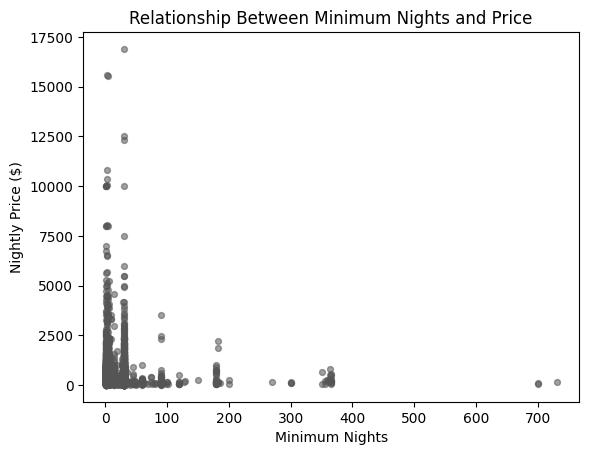

In [116]:
# scatterplot of price and minimum nights
plt.scatter(listings["minimum_nights"], listings["price"], alpha=0.55, s=18, color="#555555")
plt.xlabel("Minimum Nights")
plt.ylabel("Nightly Price ($)")
plt.title("Relationship Between Minimum Nights and Price")
plt.show()

The relationship between minimum nights and price is very weakly negative. The Pearson correlation is -0.03 and the Spearman correlation is -0.07. This indicates that minimum stay requirements have little association with price. The scatterplot shows that the highest nightly prices are mostly found among listings with shorter minimum stays. However, prices vary considerably within this group and there are relatively few listings with very long minimum stay requirements. Minimum nights does not appear to be a strong indicator of nightly price. For the real estate firm, this suggests that minimum stay requirements may be more relevant to how a property is operated than to how much it can charge per night. 

#### Price and Number of reviews

I'm examining the relationship between price and number of reviews. I want to see how the number of reviews relates to nightly prices.

In [117]:
# correlation between price and number of reviews
pearson = listings["number_of_reviews"].corr(listings["price"], method="pearson")
spearman = listings["number_of_reviews"].corr(listings["price"], method="spearman")

print("Pearson correlation:", round(pearson, 2))
print("Spearman correlation:", round(spearman, 2))

Pearson correlation: -0.06
Spearman correlation: 0.0


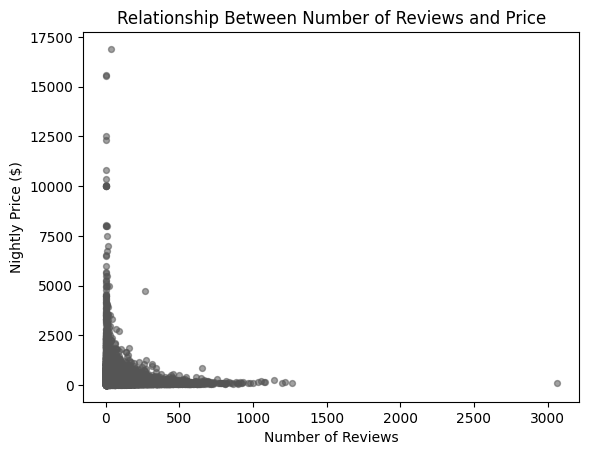

In [118]:
# scatterplot of price and number of reviews
plt.scatter(listings["number_of_reviews"], listings["price"], alpha=0.55, s=18, color="#555555")
plt.xlabel("Number of Reviews")
plt.ylabel("Nightly Price ($)")
plt.title("Relationship Between Number of Reviews and Price")
plt.show()

There appeats to be little to no relationship between the number of reviews and nightly price. The Pearson correlation is -0.06 and the Spearman correlation is 0.00, showing that listings with more reviews do not consistently have higher or lower prices. The scatterplot shows that most listings have relatively few reviews but their nightly prices vary widely. Some of the most expensive properties have very few reviews while listings with hundreds of reviews are generally concentrated at lower prices. This could be because expensive properties receive fewer bookings, although the number of reviews alone cannot confirm this. 

#### Price and Review Ratings

I'm examining the relationship between review rating and nightly price. I'm interested in seeing how prices differ across ratings and if highly rated listings tend to charge more per night.

In [119]:
# correlation between review rating and price
pearson = listings["review_scores_rating"].corr(listings["price"], method="pearson")
spearman = listings["review_scores_rating"].corr(listings["price"], method="spearman")

print("Pearson correlation:", round(pearson, 2))
print("Spearman correlation:", round(spearman, 2))

Pearson correlation: 0.04
Spearman correlation: 0.13


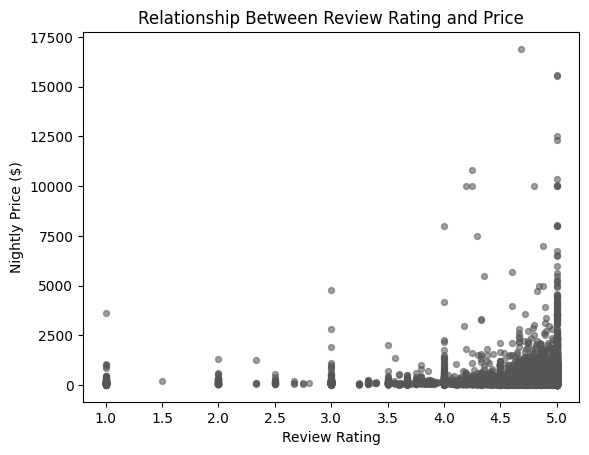

In [120]:
# scatterplot of price and review rating
plt.scatter(listings["review_scores_rating"], listings["price"], alpha=0.55, s=18, color="#555555")
plt.xlabel("Review Rating")
plt.ylabel("Nightly Price ($)")
plt.title("Relationship Between Review Rating and Price")
plt.show()

The relationship between review rating and nightly price is very weakly positive. The Pearson correlation is 0.04 and the Spearman correlation is 0.13, showing that higher ratings have little association with higher nightly prices. The scatterplot shows that most listings have ratings between 4.0 and 5.0, with a particularly large concentration near 5.0. Although many of the most expensive listings have high ratings, there are also plenty of lower priced listings with similarly high ratings. This suggests that a high review rating does not necessarily mean a property can charge more per night. 

#### Price and Superhost Status

Price is a numerical variable and superhost status is categorical. I want to compare nightly prices between listings with superhost and non-superhost hosts to see if there are any noticeable differences in pricing.

In [121]:
# summary stats for price by superhost status
listings.groupby("host_is_superhost")["price"].agg(["count", "mean", "median", "std"]).round(2)

,count,mean,median,std
host_is_superhost,,,,
0.00,12195,251.83,141.00,564.11
1.00,12993,212.62,147.00,261.28


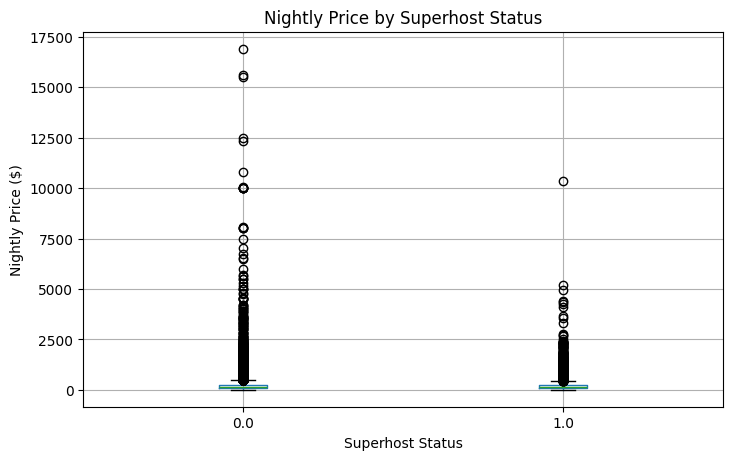

In [122]:
# boxplot of price by superhost status
listings.boxplot(column="price", by="host_is_superhost", figsize=(8, 5))
plt.xlabel("Superhost Status")
plt.ylabel("Nightly Price ($)")
plt.title("Nightly Price by Superhost Status")
plt.suptitle("")
plt.show()

Nightly prices are fairly similar between superhost and non-superhost listings. Superhosts have a slightly higher median price of \\$147 compared to \\$141 for non-superhosts. However, non-superhosts have a higher average price of \\$251.83 compared to \\$212.62 for superhosts. The boxplot shows that non-superhost listings have more extreme prices, including some above \\$15,000 per night which helps explain their higher average. Since the median prices are so close, superhost status does not appear to make a large difference in typical nightly prices. 

#### Price and Instant Bookable

Price is a numerical variable and instant bookable is categorical. I'm comparing the nightly prices of listings that allow instant booking with those that require host approval to see if this booking feature is associated with differences in price.

In [123]:
# summary stats for price by instant bookable
listings.groupby("instant_bookable")["price"].agg(["count", "mean", "median", "std"]).round(2)

,count,mean,median,std
instant_bookable,,,,
0,18826,232.54,138.00,453.01
1,6362,228.82,159.00,378.99


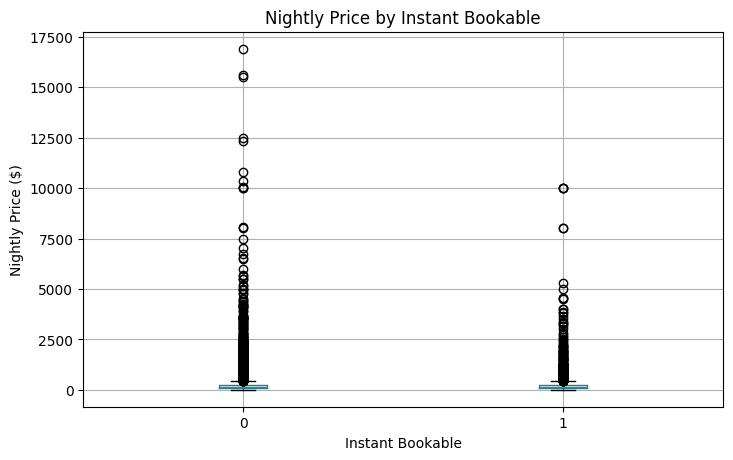

In [124]:
# boxplot of price by instant bookable
listings.boxplot(column="price", by="instant_bookable", figsize=(8, 5))
plt.xlabel("Instant Bookable")
plt.ylabel("Nightly Price ($)")
plt.title("Nightly Price by Instant Bookable")
plt.suptitle("")
plt.show()

Listings that allow instant booking have a higher median nightly price of \\$159 compared to \\$138 for listings that require host approval. However, the average prices are very similar, since it's \\$228.82 for instant bookable listings and \\$232.54 for non-instant bookable listings. The boxplot shows that both groups have a wide range of prices although listings without instant booking have more extreme outliers, including prices above \\$15,000. This helps explain why their average price is slightly higher despite having a lower median. Instant booking appears to be associated with a small difference in typical nightly prices. For the real estate firm, this suggests that offering instant booking could be worth considering but the data doesn't show that enabling this feature would directly increase prices alone.

#### Price and Room Type

Price is a numerical variable and room type is categorical. I'm examining how nightly prices differ across room types, including entire homes, private rooms, and shared rooms, to understand how the type of space being rented relates to pricing.

In [125]:
# summary statistics for price by room type
listings.groupby("room_type")["price"].agg(["count", "mean", "median", "std"]).round(2)

,count,mean,median,std
room_type,,,,
Entire home/apt,19311,270.85,171.00,459.37
Hotel room,81,893.64,321.00,2169.58
Private room,5697,92.40,68.00,160.25
Shared room,99,43.78,36.00,42.36


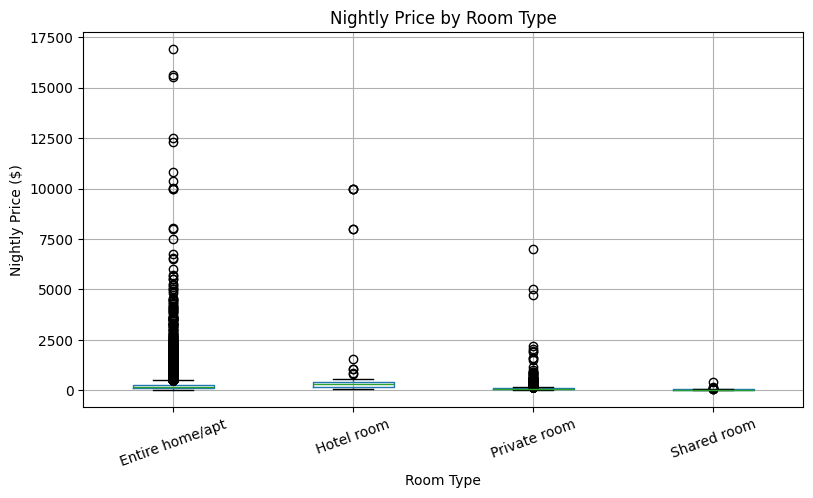

In [126]:
# boxplot of price by room type
listings.boxplot(column="price", by="room_type", figsize=(9, 5))
plt.xlabel("Room Type")
plt.ylabel("Nightly Price ($)")
plt.title("Nightly Price by Room Type")
plt.suptitle("")
plt.xticks(rotation=20)
plt.show()

Nightly prices vary a lot across room types. Hotel rooms have the highest median price at \\$321 followed by entire homes and apartments at \\$171, private rooms at \\$68, and shared rooms at \\$36. The boxplot also shows that entire homes and apartments have the most extreme prices with some listings exceeding \\$15,000 per night. Although hotel rooms have the highest average price of \\$893.64, there are only 81 hotel room listings compared to 19,311 entire homes and apartments, so this difference should be interpreted carefully. These findings suggest that room type is an important factor in understanding nightly prices, especially since renting an entire property generally costs more than renting a private or shared room. For the real estate firm, this could mean that entire homes and apartments may offer more potential for higher nightly rates but the cost of purchasing and operating these properties would also need to be considered.

#### Price and Property Type

Price is a numerical variable and property type is categorical. I'm examine how nightly prices differ across property types to see which types of properties tend to have higher prices.

In [127]:
# summary statistics for price by property type
listings.groupby("property_type")["price"].agg(["count", "mean", "median", "std"]).round(2)

,count,mean,median,std
property_type,,,,
Barn,9,141.00,105.00,117.32
Boat,8,521.75,180.00,924.59
Bus,1,68.00,68.00,NaN
Camper/RV,88,99.11,84.50,61.85
Campsite,4,157.25,76.50,197.69
Casa particular,7,243.29,166.00,218.95
Castle,5,916.60,437.00,1022.37
Cave,1,234.00,234.00,NaN
Dome,1,205.00,205.00,NaN


In [128]:
# summary stats for price by top 10 property type
common_property_types = listings["property_type"].value_counts().head(10).index
property_prices = listings[listings["property_type"].isin(common_property_types)]

property_prices.groupby("property_type")["price"].agg(["count", "mean", "median", "std"]).round(2)


,count,mean,median,std
property_type,,,,
Entire bungalow,325,204.93,171.00,116.19
Entire condo,1082,230.97,179.00,176.72
Entire guest suite,935,135.39,113.00,148.54
Entire guesthouse,2033,138.07,122.00,68.05
Entire home,7399,369.12,247.00,541.41
Entire rental unit,5770,165.51,144.00,98.94
Entire townhouse,452,274.14,226.50,276.24
Entire villa,372,1360.13,962.00,1615.17
Private room in home,3501,81.54,63.00,168.79


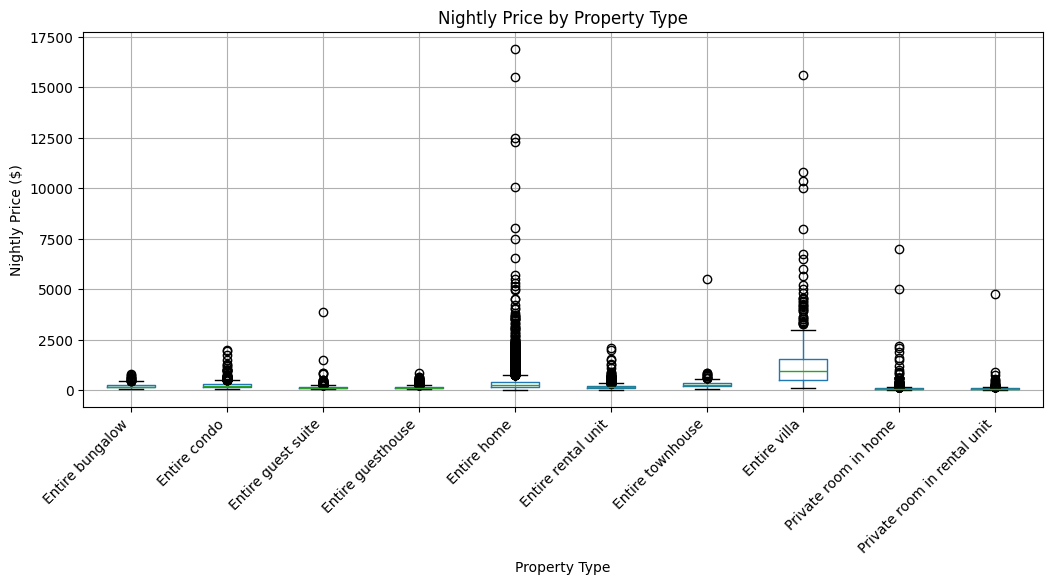

In [129]:
# boxplot of price by property type
property_prices.boxplot(column="price", by="property_type", figsize=(12, 5))
plt.xlabel("Property Type")
plt.ylabel("Nightly Price ($)")
plt.title("Nightly Price by Property Type")
plt.suptitle("")
plt.xticks(rotation=45, ha="right")
plt.show()

For the boxplot, I focused on the 10 most common property types because there are many different property types in the dataset. Including all of them would make the graph too crowded and difficult to read especially since some categories have very few listings. Among the 10 most common types, entire villas have the highest median nightly price at \\$962 followed by entire homes at \\$247 and entire townhouses at \\$226.50. Private rooms in homes have the lowest median at \\$63. The boxplot shows that villas generally have higher prices while entire homes have some of the most extreme outliers. This suggests that property type can make a large difference in nightly price.

#### Price and Neighbourhood Group

Price is a numerical variable and property type is categorical. I'm comparing nightly prices across different areas of Los Angeles to see how location relates to pricing.

In [130]:
# summary statistics for price by neighbourhood group
listings.groupby("neighbourhood_group_cleansed")["price"].agg(["count", "mean", "median", "std"]).round(2)

,count,mean,median,std
neighbourhood_group_cleansed,,,,
City of Los Angeles,11084,240.14,145.00,395.72
Other Cities,11327,232.70,147.00,500.66
Unincorporated Areas,2777,193.06,128.00,266.74


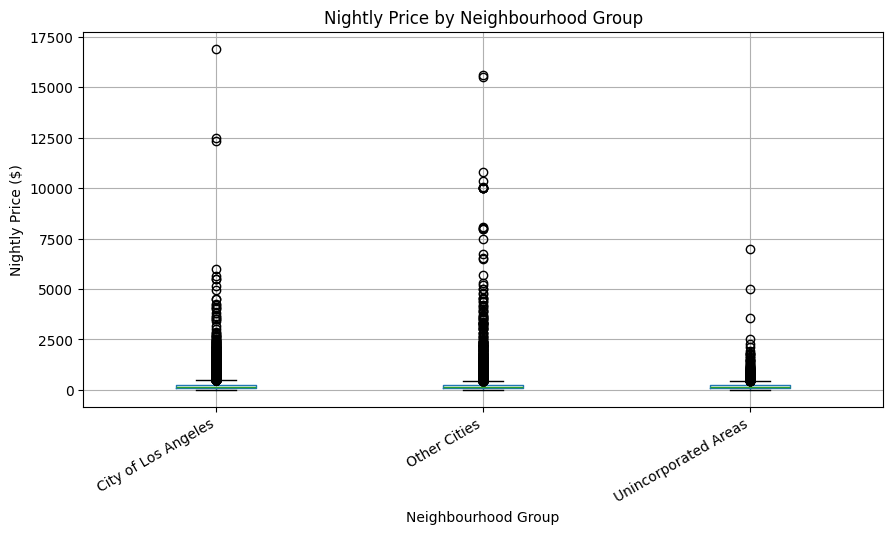

In [131]:
# boxplot of price by neighbourhood group
listings.boxplot(column="price", by="neighbourhood_group_cleansed", figsize=(10, 5))
plt.xlabel("Neighbourhood Group")
plt.ylabel("Nightly Price ($)")
plt.title("Nightly Price by Neighbourhood Group")
plt.suptitle("")
plt.xticks(rotation=30, ha="right")
plt.show()

Nightly prices are fairly similar across the three neighbourhood groups. Other Cities have the highest median price at \\$147, City of Los Angeles has a median of \\$145 and Unincorporated Areas has \\$128. However, the City of Los Angeles has the highest mean price at \\$240.14. The boxplot shows that all three groups have expensive outliers. The highest prices are in the City of Los Angeles and Other Cities. The differences in median prices are relatively small, suggesting that these broad neighbourhood groups don't explain much of the variation in nightly prices. For the firm, it might be more useful to compare individual neighbourhoods since prices could vary considerably within each group.

#### Price and Neighbourhood

Price is a numerical variable and property type is categorical. I'm examining how nightly prices differ between individual neighbourhoods in Los Angeles to see if there are larger differences than those found between neighbourhood groups.

In [132]:
# summary stats for price by neighbourhood
listings.groupby("neighbourhood_cleansed")["price"].agg(["count", "mean", "median", "std"]).round(2)

,count,mean,median,std
neighbourhood_cleansed,,,,
Acton,8,124.25,103.00,68.35
Adams-Normandie,25,77.64,50.00,54.67
Agoura Hills,35,309.74,207.00,337.27
Agua Dulce,15,310.40,125.00,442.68
Alhambra,486,148.52,117.00,167.58
...,...,...,...,...
Willowbrook,31,166.61,110.00,145.38
Wilmington,6,169.67,181.00,60.43
Windsor Square,16,156.38,142.50,78.96


In [133]:
# Summary stats for the top 10 most common neighbourhoods
listings.groupby("neighbourhood_cleansed")["price"].agg(["count", "mean", "median", "std"]).sort_values("count", ascending=False).head(10).round(2)

,count,mean,median,std
neighbourhood_cleansed,,,,
Long Beach,1238,193.09,151.50,141.92
Venice,850,301.16,208.50,270.27
Hollywood,812,170.47,130.00,149.34
Santa Monica,790,231.83,182.00,222.51
West Hollywood,647,218.01,168.00,200.63
Downtown,539,159.43,146.00,84.20
Beverly Hills,537,509.15,185.00,1252.24
Alhambra,486,148.52,117.00,167.58
Glendale,474,186.36,149.50,128.48


In [134]:
[col for col in listings.columns if "neigh" in col.lower()]

['neighbourhood_cleansed', 'neighbourhood_group_cleansed']

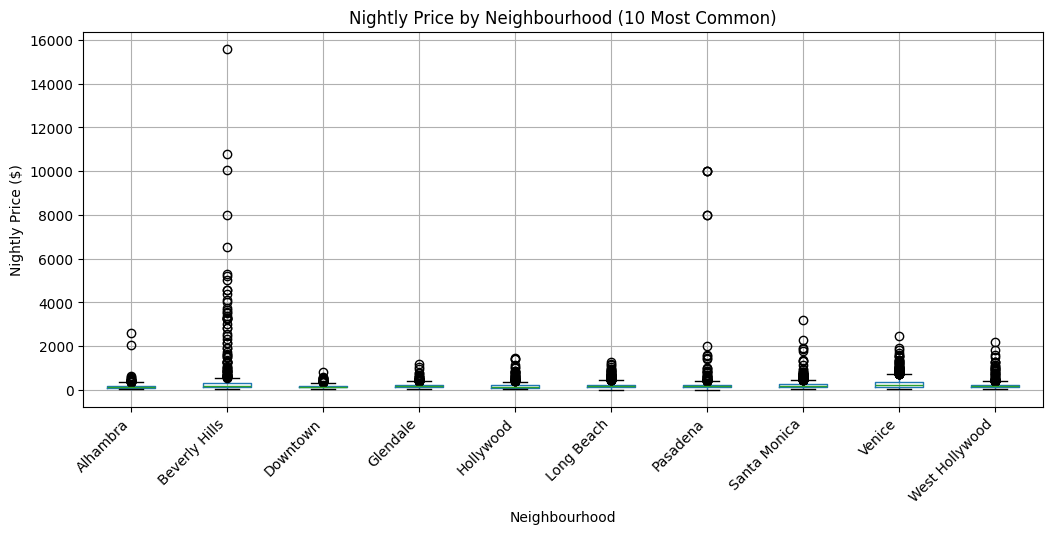

In [135]:
# boxplot of price by the top 10 common neighbourhoods
common_neighbourhoods = listings["neighbourhood_cleansed"].value_counts().head(10).index
neighbourhood_prices = listings[listings["neighbourhood_cleansed"].isin(common_neighbourhoods)]

neighbourhood_prices.boxplot(column="price", by="neighbourhood_cleansed", figsize=(12, 5))
plt.xlabel("Neighbourhood")
plt.ylabel("Nightly Price ($)")
plt.title("Nightly Price by Neighbourhood (10 Most Common)")
plt.suptitle("")
plt.xticks(rotation=45, ha="right")
plt.show()

For the boxplot I focused on the 10 most common neighbourhoods because there are 265 neighbourhoods total and showing all of them would make the graph too crowded. The boxplot shows noticeable differences in nightly prices across neighbourhoods. Beverly Hills and Venice generally have higher prices while Alhambra and Downtown have lower typical prices. Beverly Hills also has the most extreme outliers, with some listings priced above \\$15,000 per night. These differences are more noticeable than those between the three broader neighbourhood groups. This suggests that looking at individual neighbourhoods could be more useful when comparing property prices and deciding where to invest.

#### Accommodates and Bedrooms

I chose to examine accommodates and bedrooms because I want to see how the number of bedrooms relates to how many guests a listing can accommodate and how strong this relationship is. This could help identify differences in guest capacity among properties with the same number of bedrooms.

I hypothesize that there will be a strong positive relationship between bedrooms and accommodates and listings that have more bedrooms will generally be able to accommodate more guests.

In [136]:
# correlation between accommodates and bedrooms
pearson = listings["accommodates"].corr(listings["bedrooms"], method="pearson")
spearman = listings["accommodates"].corr(listings["bedrooms"], method="spearman")

print("Pearson correlation:", round(pearson, 2))
print("Spearman correlation:", round(spearman, 2))

Pearson correlation: 0.85
Spearman correlation: 0.8


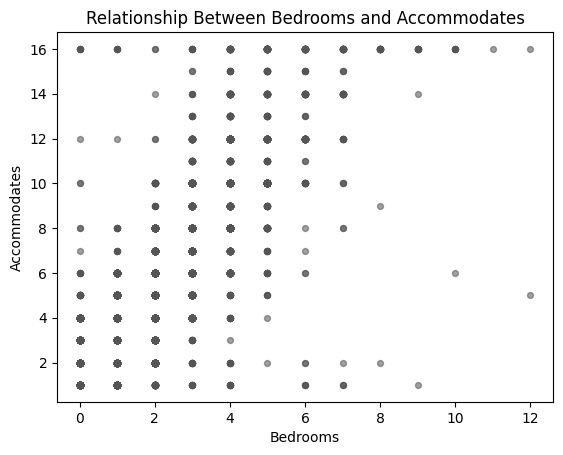

In [137]:
# scatterplot of accommodates and bedrooms
plt.scatter(listings["bedrooms"], listings["accommodates"], alpha=0.55, s=18, color="#555555")
plt.xlabel("Bedrooms")
plt.ylabel("Accommodates")
plt.title("Relationship Between Bedrooms and Accommodates")
plt.show()

There is a strong positive relationship between bedrooms and accommodates which supports my hypothesis. The Pearson correlation is 0.85 and the Spearman correlation is 0.80. This indicates that listings with more bedrooms generally accommodate more guests. The scatterplot also shows that guest capacity varies among listings with the same number of bedrooms. For example, some 3 bedroom properties accommodate 6 guests, while others accommodate 10 or more. This suggests that the number of bedrooms is an important factor in guest capacity but other features, such as the number of beds may also play a role. For the firm this could mean that properties with similar bedroom counts may have different guest capacities, which could affect how they are marketed to potential guests.

#### Superhost Status and Instant Bookable
I chose to examine superhost status and instant bookable because both are categorical variables related to how listings are managed. I want to see if superhosts are more likely to offer instant booking than non-superhosts.

I hypothesize that a higher percentage of superhosts will offer instant booking compared to non-superhosts.

In [138]:
# cross tab of superhost status and instant bookable
pd.crosstab(listings["host_is_superhost"], listings["instant_bookable"])

instant_bookable,0,1
host_is_superhost,,
0.00,8866,3329
1.00,9960,3033


In [139]:
# percentage of instant bookable listings by superhost status
pd.crosstab(listings["host_is_superhost"], listings["instant_bookable"], normalize="index").mul(100).round(2)

instant_bookable,0,1
host_is_superhost,,
0.00,72.70,27.30
1.00,76.66,23.34


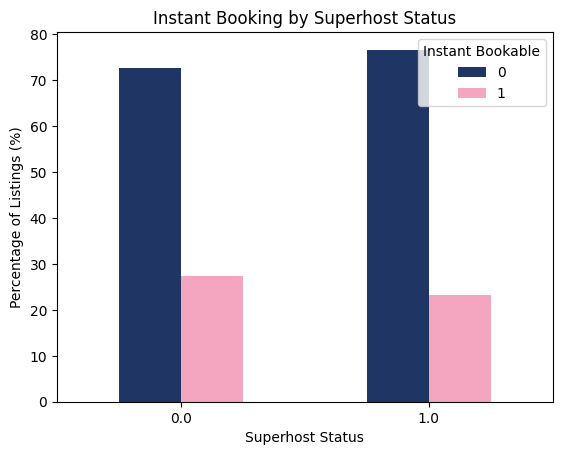

In [140]:
# bar chart of instant bookable by superhost status
pd.crosstab(listings["host_is_superhost"], listings["instant_bookable"], normalize="index").mul(100).plot(kind="bar", color=["#1F3564", "#F4A6C1"], rot=0)
plt.xlabel("Superhost Status")
plt.ylabel("Percentage of Listings (%)")
plt.title("Instant Booking by Superhost Status")
plt.legend(title="Instant Bookable")
plt.show()


The cross-tabulation shows that instant booking is slightly more common among non-superhosts, at 27.30% compared to 23.34% of superhosts. However, the difference is only 3.96 percentage points so the two groups are fairly similar. This doesn't support my hypothesis that superhosts would be more likely to offer instant booking. The bar chart also shows that most listings in both groups don't offer instant booking. There doesn't appear to be much of a relationship between superhost status and instant booking.

## Statistical Inference

Bootstrap resampling was used to estimate 95% confidence intervals for differences in mean nightly prices across listing groups.

The analysis compares pricing between entire homes/apartments and private rooms, as well as Superhost and non-Superhost listings.

In [141]:
# descriptive stats for entire home/apartmnts
listings[listings["room_type"] == "Entire home/apt"]["price"].describe()

count   19311.00
mean      270.85
std       459.37
min        10.00
25%       119.00
50%       171.00
75%       275.00
max     16903.00
Name: price, dtype: float64

In [142]:
# descriptive stats for private rooms
listings[listings["room_type"] == "Private room"]["price"].describe()

count   5697.00
mean      92.40
std      160.25
min        9.00
25%       52.00
50%       68.00
75%       95.00
max     7007.00
Name: price, dtype: float64

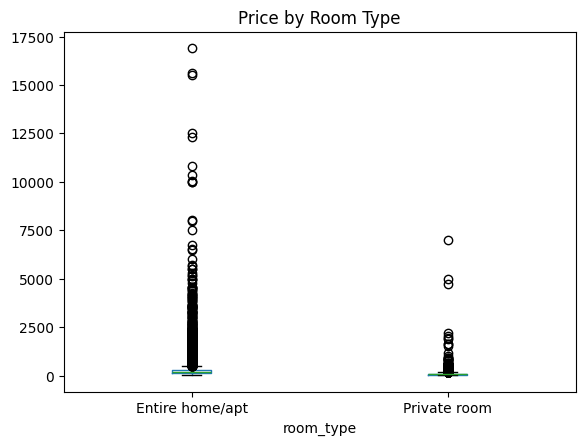

In [143]:
# boxplots for entire home/apt and private room
listings[listings["room_type"].isin(["Entire home/apt", "Private room"])].boxplot(column="price", by="room_type", grid=False)
plt.suptitle("")
plt.title("Price by Room Type")
plt.show()

The average nightly price for an entire home or apartment is \\$270.85 and is \\$92.40 for a private room. The difference between these means is \\$178.45. This is important because room type may influence how much guests are willing to pay for a listing. Entire homes generally offer more privacy and space which could help explain the price difference. For hosts, understanding this difference can help inform pricing decisions. 

In [144]:
rng = np.random.default_rng(505)

In [145]:
# store the prices for each room type as arrays so we can bootstrap
entire = listings[listings["room_type"] == "Entire home/apt"]["price"].to_numpy()
private = listings[listings["room_type"] == "Private room"]["price"].to_numpy()

In [146]:
# generate 1000 bootstrap samples and calculate the difference in mean prices
B = 1000
boot_diffs = np.array([rng.choice(entire, size=entire.size, replace=True).mean() - rng.choice(private, size=private.size, replace=True).mean() for _ in range(B)])
lo, hi = np.percentile(boot_diffs, [2.5, 97.5])
print(f"95% bootstrap CI for the difference in means: ({lo:,.2f}, {hi:,.2f})")

95% bootstrap CI for the difference in means: (170.86, 186.43)


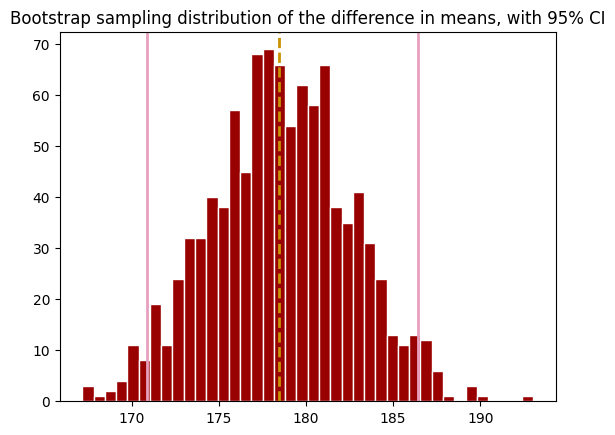

In [147]:
# Bootstrap distribution for entire homes vs. private rooms
plt.hist(boot_diffs, bins=40, color="#990000", edgecolor="white")
plt.axvline(lo, color="#E8A0BF", lw=2)
plt.axvline(hi, color="#E8A0BF", lw=2)
plt.axvline(entire.mean() - private.mean(), color="#C89200", lw=2, ls="--")
plt.title("Bootstrap sampling distribution of the difference in means, with 95% CI")
plt.show()

The 95% bootstrap confidence interval for the difference in average nightly prices is \\$170.86 to \\$186.43. Since this range doesn't include zero, the difference is statistically significant. This suggests that entire homes and apartments tend to have higher average nightly prices than private rooms in Los Angeles.

In [148]:
# descriptive stats for superhosts
listings[listings["host_is_superhost"] == 1]["price"].describe()

count   12993.00
mean      212.62
std       261.28
min         9.00
25%        96.00
50%       147.00
75%       238.00
max     10350.00
Name: price, dtype: float64

In [149]:
# descriptive statistics for non-superhosts
listings[listings["host_is_superhost"] == 0]["price"].describe()

count   12195.00
mean      251.83
std       564.11
min         9.00
25%        86.00
50%       141.00
75%       240.00
max     16903.00
Name: price, dtype: float64

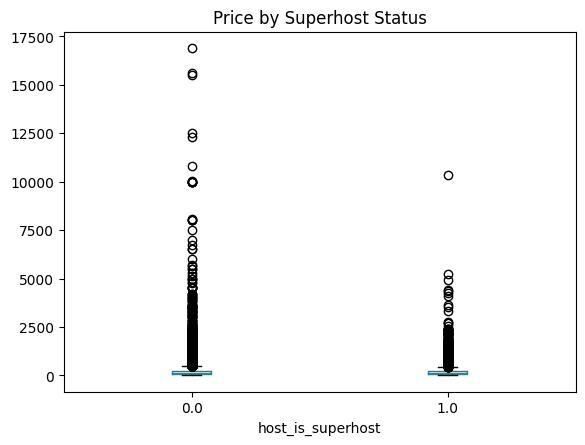

In [150]:
# boxplots for superhosts and non-superhosts
listings[listings["host_is_superhost"].isin([1, 0])].boxplot(column="price", by="host_is_superhost", grid=False)
plt.suptitle("")
plt.title("Price by Superhost Status")
plt.show()

The mean nightly price for Superhost listings is \\$212.62 and for non-Superhost listings its \\$251.83. The difference between the means of $39.21. I found this interesting because I expected Superhosts to have higher prices given their reputation and experience. The boxplot shows that non-Superhosts have more extreme high-price outliers which could be affecting their average. This difference is worth looking into because it could help hosts understand how Superhost status relates to pricing.

In [151]:
# store prices for superhosts and non-superhosts as arrays for bootstrapping
superhost = listings[listings["host_is_superhost"] == 1]["price"].to_numpy()
non_superhost = listings[listings["host_is_superhost"] == 0]["price"].to_numpy()

In [152]:
# generate 1000 bootstrap samples and calculate the difference in mean prices
B = 1000
boot_diffs = np.array([rng.choice(superhost, size=superhost.size, replace=True).mean() - rng.choice(non_superhost, size=non_superhost.size, replace=True).mean() for _ in range(B)])
lo, hi = np.percentile(boot_diffs, [2.5, 97.5])
print(f"95% bootstrap CI for the difference in means: ({lo:,.2f}, {hi:,.2f})")

95% bootstrap CI for the difference in means: (-49.92, -28.66)


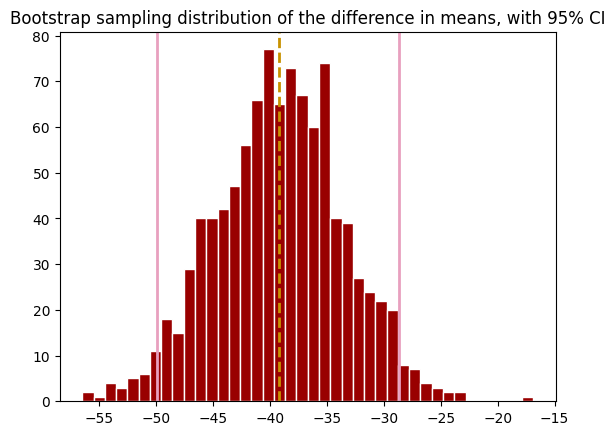

In [153]:
# bootstrap distribution
plt.hist(boot_diffs, bins=40, color="#990000", edgecolor="white")
plt.axvline(lo, color="#E8A0BF", lw=2)
plt.axvline(hi, color="#E8A0BF", lw=2)
plt.axvline(superhost.mean() - non_superhost.mean(), color="#C89200", lw=2, ls="--")
plt.title("Bootstrap sampling distribution of the difference in means, with 95% CI")
plt.show()

The 95% bootstrap confidence interval for the difference in average nightly prices between Superhosts and non-Superhosts is -\\$49.92 to -\\$28.66. Since this range doesn't include zero the difference is statistically significant. This suggests that non-Superhost listings tend to have higher average nightly prices than Superhost listings in LA.

## Probability Distribution Modeling

A log-normal distribution was fitted to nightly prices to evaluate how well the model represents the observed data.

The distribution was then refitted to listings priced below $500 and used to estimate probabilities for selected nightly price ranges

In [154]:
price_params = lognorm.fit(listings.price)
print(price_params)

(np.float64(0.8384386930092758), 8.090086615430346, np.float64(143.24101688738554))


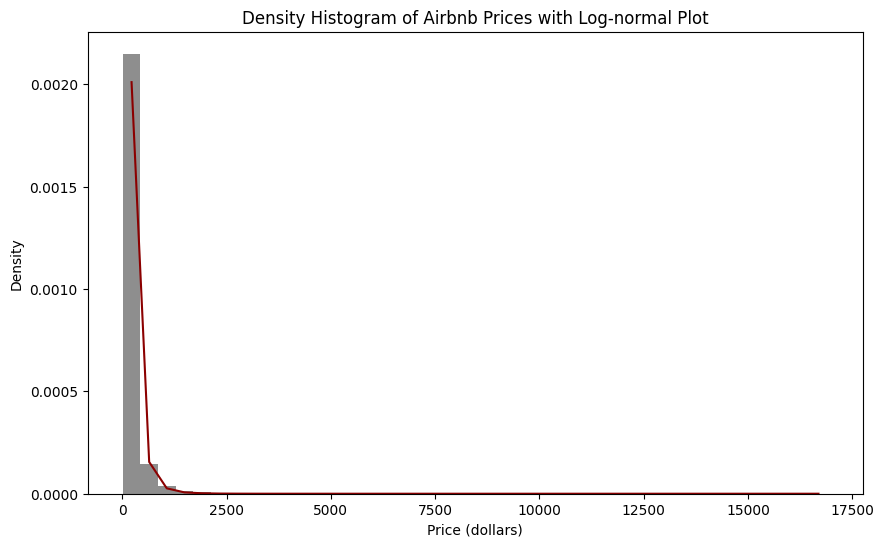

In [155]:
# log normal model compared with Airbnb prices
figure = plt.figure(figsize=(10, 6))

axes = figure.add_subplot(1, 1, 1)
n, bins, patches = axes.hist(listings.price, color="DimGray", density=True, bins=40, alpha=0.75)

axes.set_xlabel("Price (dollars)")
axes.set_ylabel("Density")
axes.set_title("Density Histogram of Airbnb Prices with Log-normal Plot")

xs = [(b2 + b1)/2 for b1, b2 in zip(bins, bins[1:])]

ys = [lognorm.pdf(k, *price_params) for k in xs]
axes.plot(xs, ys, color="darkred")

plt.show()

I chose the log-normal distribution to model Airbnb nightly prices because it is designed for positive values and has a long right tail, which matches the pattern of most listings having lower prices and a small number having very high prices. The histogram shows that a few extremely expensive listings stretch the x-axis which makes it difficult to see how well the curve fits the prices of most listings. Although the log-normal distribution captures the right-skewed shape of the data, it's difficult to evaluate the fit properly because of these extreme values.

4. Re-fit your distributional model to price, but this time limit the values of price to below \\$500. 
5. In a Markdown cell, write one sentence to answer this question: Did the fit improve?
6. Using code and Markdown cells, complete the following:
   * Write three questions that you can answer using this distributional model (e.g., “What is the probability of finding an Airbnb rental with a price under $300/night?”).
   * Analyze data to answer each question you posed.
   * Write a one-sentence answer to each question you posed.

Add as many code and Markdown cells as you need.

In [156]:
# fit log-normal distribution to prices below $500
prices_below_500 = listings[listings["price"] < 500]["price"]

price_params_500 = lognorm.fit(prices_below_500)
print(price_params_500)

(np.float64(0.599678662236653), -2.9715899980442257, np.float64(137.59466955815427))


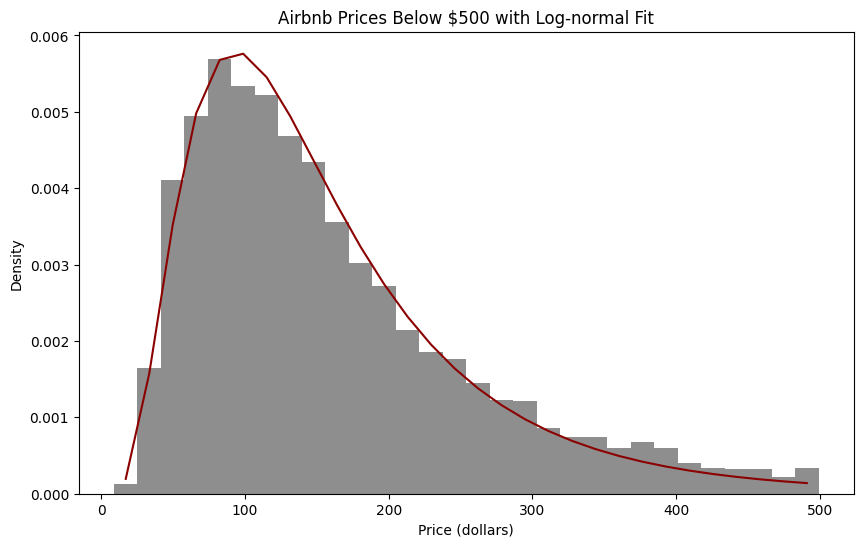

In [157]:
# Log-normal model compared with Airbnb prices below $500
figure = plt.figure(figsize=(10, 6))
axes = figure.add_subplot(1, 1, 1)
n, bins, patches = axes.hist(prices_below_500, color="DimGray", density=True, bins=30, alpha=0.75)

axes.set_xlabel("Price (dollars)")
axes.set_ylabel("Density")
axes.set_title("Airbnb Prices Below $500 with Log-normal Fit")

xs = [(b2 + b1)/2 for b1, b2 in zip(bins, bins[1:])]

ys = [lognorm.pdf(k, *price_params_500) for k in xs]
axes.plot(xs, ys, color="darkred")

plt.show()

Yes, the fit improved after limiting prices to below $500 because the curve matches the histogram more closely and better reflects the overall distribution of prices.

##### Question 1: What is the probability that an Airbnb listing costs between \\$100 and \\$200 per night?

In [158]:
# probability of a price between $100 and $200
lognorm.cdf(200, *price_params_500) - lognorm.cdf(100, *price_params_500)

np.float64(0.42717388236755793)

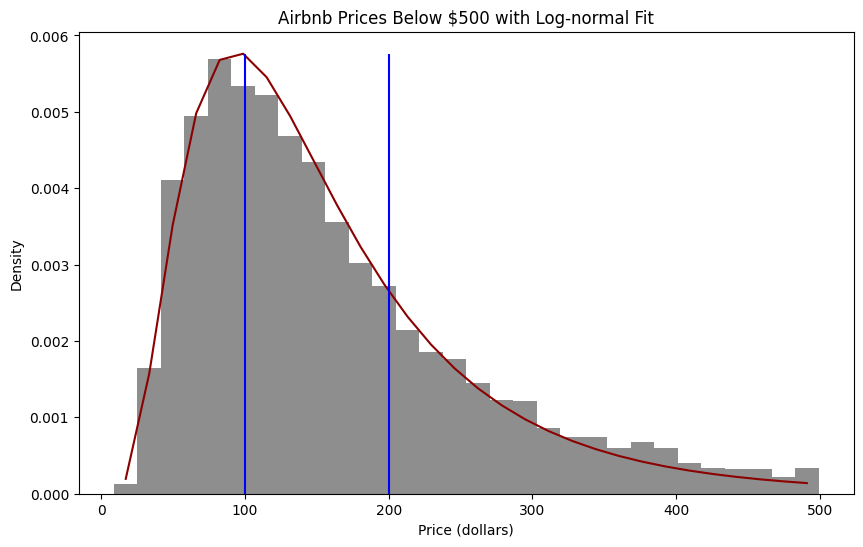

In [159]:
figure = plt.figure(figsize=(10,6))

axes = figure.add_subplot(1, 1, 1)
n, bins, patches = axes.hist(prices_below_500, color="DimGray", density=True, bins=30, alpha=0.75)

axes.set_xlabel("Price (dollars)")
axes.set_ylabel("Density")
axes.set_title("Airbnb Prices Below $500 with Log-normal Fit")

xs = [(b2 + b1)/2 for b1, b2 in zip(bins, bins[1:])]

ys = [lognorm.pdf(k, *price_params_500) for k in xs]
axes.plot(xs, ys, color="darkred")

axes.vlines(100, ymin=0.0, ymax=max(ys), color="blue")
axes.vlines(200, ymin=0.0, ymax=max(ys), color="blue")

plt.show()
plt.close()

There's a 42.7% chance that an Airbnb listing priced below \\$500 costs between \\$100 and \\$200 per night.

##### Question 2: What is the probability that an Airbnb listing costs less than \\$250 per night?

In [160]:
# probability of a price below $250
lognorm.cdf(250, *price_params_500)

np.float64(0.8450627795309953)

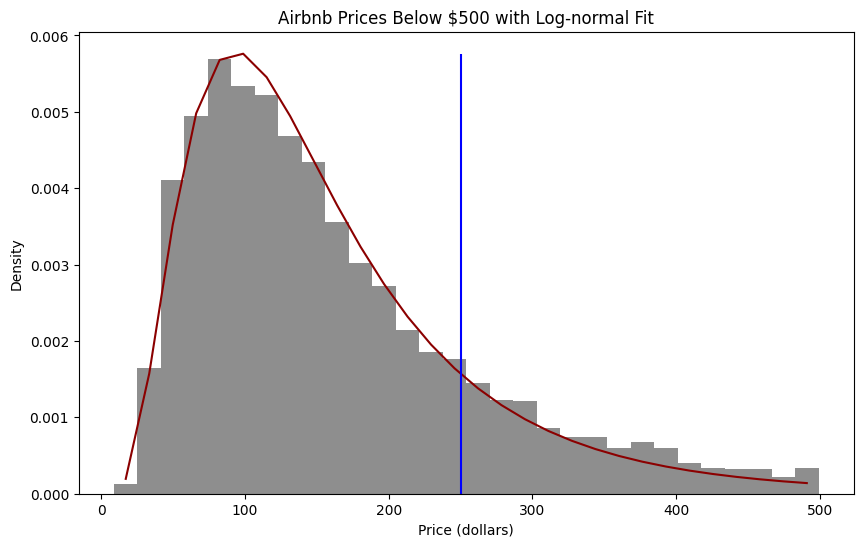

In [161]:
figure = plt.figure(figsize=(10,6))

axes = figure.add_subplot(1, 1, 1)
n, bins, patches = axes.hist(prices_below_500, color="DimGray", density=True, bins=30, alpha=0.75)

axes.set_xlabel("Price (dollars)")
axes.set_ylabel("Density")
axes.set_title("Airbnb Prices Below $500 with Log-normal Fit")

xs = [(b2 + b1)/2 for b1, b2 in zip(bins, bins[1:])]

ys = [lognorm.pdf(k, *price_params_500) for k in xs]
axes.plot(xs, ys, color="darkred")

axes.vlines(250, ymin=0.0, ymax=max(ys), color="blue")

plt.show()
plt.close()

There's an 84.5% chance that an Airbnb listing priced below \\$500 costs less than \\$250 per night.

##### Question 3: What is the probability that an Airbnb listing costs less than $75 per night?

In [162]:
# probability of a price below $75
lognorm.cdf(75, *price_params_500)

np.float64(0.17178881641554722)

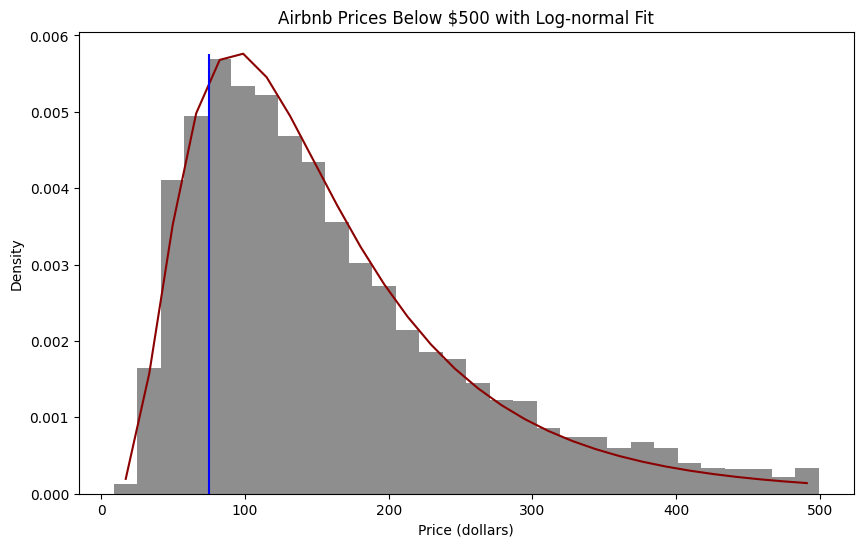

In [163]:
figure = plt.figure(figsize=(10,6))

axes = figure.add_subplot(1, 1, 1)
n, bins, patches = axes.hist(prices_below_500, color="DimGray", density=True, bins=30, alpha=0.75)

axes.set_xlabel("Price (dollars)")
axes.set_ylabel("Density")
axes.set_title("Airbnb Prices Below $500 with Log-normal Fit")

xs = [(b2 + b1)/2 for b1, b2 in zip(bins, bins[1:])]

ys = [lognorm.pdf(k, *price_params_500) for k in xs]
axes.plot(xs, ys, color="darkred")

axes.vlines(75, ymin=0.0, ymax=max(ys), color="blue")

plt.show()
plt.close()

There's a 17.2% chance that an Airbnb listing priced below \\$500 costs less than \\$75 per night.

## Limitations and Next Steps



One limitation of my analysis is that I removed listings with missing values or unusual information, which could introduce selection bias. I excluded listings that appeared to have errors, such as unusually high prices or inconsistent bed and bedroom counts. However, there is a chance that some of these listings may have been legitimate so removing them could affect how well the remaining data represents Airbnb listings in Los Angeles. Another limitation is that my analysis examined the relationship between price and individual listing characteristics without accounting for other factors. The difference in average prices between entire homes and private rooms could be partly explained by differences in location or property size. I also refitted the log-normal distribution using only listings priced below $500 which means that model doesn't represent higher priced properties. Additionally, the dataset is from 2025 so the prices and listing characteristics may have changed since the data was collected.

To address these limitations, I could analyze multiple listing characteristics together to better understand what influences nightly prices. Comparing properties within the same neighborhood and room type could also help account for differences between listings. I would also want to use more recent data and examine how prices change throughout the year, since the current analysis doesn't account for seasonal demand. The dataset includes estimated occupancy and revenue, but I would need actual booking data and information about expenses, such as cleaning, maintenance, and property costs to get a better idea of how profitable these listings are.

## Key Findings and Recommendations


I found that room type, property size, and location all likely play an important role in Airbnb pricing in Los Angeles. Entire homes and apartments had an average nightly price of \\$270.85, while private rooms averaged \\$92.40. The bootstrap results also showed a statistically significant difference in average prices between these groups. Based on this, I think entire homes and apartments could be good investment options. How often they're booked and how much they cost to maintain can also affect their profitability.

Property size was also strongly associated with price. Listings with more bedrooms and space for additional guests generally charged higher nightly rates. Properties that can accommodate families or groups could be good options for investors interested in earning rental income. I also found that Superhosts had an average nightly price of \\$212.62 and non-Superhosts averaged \\$251.83. I found this surprising since Superhosts are recognized for providing good guest experiences. This suggests that Superhost status alone isn't a strong indicator of how much a property can charge per night.

Prices also varied across neighborhoods. Venice averaged \\$301.16 per night and Santa Monica averaged \\$231.83. Beverly Hills had an average nightly price of \\$509.15, with a median of only \\$185. The large difference between the mean and median suggests that a small number of expensive listings may be raising the average. If the firm uses the average alone to estimate potential rental income in Beverly Hills, it could overestimate what a typical property might earn. Looking at the median and the range of prices within each neighborhood would give the firm a better idea of what properties typically charge and help narrow down areas for further research.

Based on these findings, I would recommend that the firm look into entire homes and apartments in Venice and Santa Monica, especially properties with multiple bedrooms. Long Beach could also be an option depending on the cost of purchasing a property there. I would focus on properties that have enough expected bookings to cover their expenses and generate a profit. Before making a final decision, the firm should also review booking revenue, occupancy rates, and costs such as cleaning, maintenance, and mortgage payments. This would help identify which properties are financially worth investing in.

## References

Airbnb. (n.d.). *About Airbnb: What it is and how it works.* https://www.airbnb.com/help/article/2503 

Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical statistics for data scientists (2nd ed.)*. O’Reilly Media. https://learning.oreilly.com/library/view/practical-statistics-for/9781492072935/ch02.html

Colella, M. (2026). Week 4 Live Session Notebook [Jupyter Notebook]. University of Southern California

Colella, M. (2026). Week 5 Live Session Notebook [Jupyter Notebook]. University of Southern California

Colella, M. (2026). Week 6 Live Session Notebook [Jupyter Notebook]. University of Southern California

Geckoboard. (n.d.). *Data fallacies*. https://www.geckoboard.com/best-practice/statistical-fallacies/ 

Hubbard, M. (n.d.). *The Airbnb terms you need to know: A glossary of short-term rental terms.* The Host Co. https://thehost.co/blog-list/the-airbnb-terms-you-need-to-know-a-glossary-of-short-term-rental-terms 

Inside Airbnb. (2025, March 1). *Los Angeles, California, United States: listings.csv.gz* [Dataset]. Retrieved June 17, 2025, from https://insideairbnb.com/get-the-data/

Ned. (2026, March 21). *What is Airbnb? A guide to its evolution and travel impact.* Touch Stay. https://touchstay.com/blog/what-is-airbnb